# 034 — Original vs optimised site-specific record sets: is a full re-run justified?

Every site-specific (SS) record set was re-selected with a stronger optimisation step (minimising
the optimiser's weighted-KS objective against the GCIM). This notebook asks whether that changes
the study's result enough to re-run **every** MSA-SS analysis. The decision is all or nothing, so
the comparison is made at **study level**: on the **A0c** fit for θ and β,

$$y^{(0)}_{avg,i} = a_i - c_{avg,g[i]} = m_0 + d_{g[i]} + s_{\sigma[i]} + u_i + \varepsilon_i .$$

and on the **A3ab** regression (A0c plus four GCIM-vs-FEMA covariates) for θ. Only the SS arm
$a_i$ can change; the FEMA P695 arms ($b_j$, $c_j$) are untouched.

| step | what | needs new NLTHA? |
|---|---|---|
| 1 | which sets changed, and which structure-stripes use them | no |
| 2 | how much closer each set is to its GCIM target (the optimiser's own objective, and the log-moments) | no |
| 3 | predicted change in each $a_i$, from a logistic model fitted to the **existing** collapse outcomes | no |
| 4 | refit A0c (θ, β) and A3ab (θ) with the shifted SS arm; compare each quantity with 0.5 SE | no |
| 5 | summary of every quantity against the 0.5 SE threshold | — |

Logic: `phd_project/scripts/record_set_comparison.py`
(this notebook only loads, calls, plots and comments). Ds5-95 (`RSD595`) leads every table and figure.

In [41]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [42]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

import phd_project.scripts.record_set_comparison as rsc
import phd_project.scripts.metaregression_analysis as mra
import phd_project.scripts.fragility_data_models as fm
from phd_project.config import config

cfg = config.load_config()
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

# ---- the record sets compared (named explicitly: this notebook never follows the active
# study, so it reproduces the same comparison whatever the main line does later) ---------
SS_ORIG, SS_OPT, SS_MUS, SS_KMS = ("AvgSA_03__ks", "AvgSA_03__opt_ks",
                                   "AvgSA_03__opt_mu_sigma", "AvgSA_03__opt_ks_mu_sigma")
# The study the original sets were analysed in: its fragilities, bootstraps and dataset.
STUDY_ORIG = "AvgSA_03__ks__vs__femap695"


def _sets_dir(ss):
    """results/04_record_selection/ss/{ss}/: the stripe pickles of one SS record set."""
    return config.ss_dir(cfg, "results", "record_selection", ss)


# ---- inputs (read only) ----------------------------------------------------------------
ORIG_DIR = _sets_dir(SS_ORIG)    # original SS sets
OPT_DIR = _sets_dir(SS_OPT)      # optimised SS sets (KS objective)
# second optimisation scheme: matches only the mean and SD of each ln IM to the GCIM (not the
# KS distance), and is not required to pass KS.
MUS_DIR = _sets_dir(SS_MUS)
# third scheme ("KS + mu/sigma"): a weighted sum of the KS distance and the mean / SD errors, plus
# the KS-band penalty, and still required to pass KS.
# (This set is the main line now and may gain stripes; only the original stripes are used.)
KMS_DIR = _sets_dir(SS_KMS)
# per-site MSA fragility + flag JSONs of the ORIGINAL sets (the only ones with NLTHA results)
FRAG_ROOT = config.ss_dir(cfg, "proc_data", "structure_fragility_curves", SS_ORIG)
FLAGS_CSV = FRAG_ROOT / "site_msa_collapse_flags_AvgSA_03.csv"   # per-record 0/1 collapse flags
BOOT_ROOT = config.bootstrap_roots(cfg, STUDY_ORIG)                # {"ss", "fx", "study"}
STAT_DIR = BOOT_ROOT["study"]                                      # nb 072's output of that study
IM_TAG = "AvgSA_03"

# ---- outputs ---------------------------------------------------------------------------
OUT = cfg["proc_data"]["record_set_comparison"]      # CSV tables
FIG = cfg["results"]["record_set_comparison"]        # figures
OUT.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

# On-disk cache of the statistical-model fits (fit_cache): a fit whose inputs are unchanged is
# LOADED instead of re-bootstrapped. Every registry in this notebook gets a cache_tag naming the
# record sets behind its container, so the original, KS-, mu/sigma- and KS + mu/sigma-optimised
# containers (which share im_tag, quantity and storeys) never overwrite each other's files.
FIT_CACHE = OUT / "models"
# The tags are the record-set ids without the IM prefix ("AvgSA_03__ks" -> "ks").
TAG_ORIG, TAG_KS, TAG_MUS, TAG_KMS = (s.split("__", 1)[1] for s in (SS_ORIG, SS_OPT, SS_MUS, SS_KMS))

N_REPS = 200          # every bootstrap / Monte Carlo count in this notebook (user: diagnostic)
SEED = 34             # the notebook number, so the draws are reproducible


def savefig(fig, name):
    # every saved figure gets an opaque white background (CLAUDE.md)
    fig.savefig(FIG / name, dpi=200, bbox_inches="tight", facecolor="w")

## 1 — Which record sets changed?

Both folders are loaded and keyed on each pickle's **own** `cond_iml`. The filename IML is rounded to
3 dp (0.6049 is stored as `00pt605`), so keying on the filename would lose 64 of the sets the MSA ran.

Each set is then matched to the MSA structure-stripes that ran it. The match also checks that the
flag JSON's 30 record names are the pickle's 30 filenames **in the same order**, so slot $k$ of the
collapse flags really is record $k$ of the set. Wherever the 3- and 5-storey structures at a site ran
the same IML they ran the same 30 records, so a change to that set moves **both** rows.

In [43]:
t0 = time.time()
orig = rsc.load_record_sets(ORIG_DIR)
opt = rsc.load_record_sets(OPT_DIR)
mus = rsc.load_record_sets(MUS_DIR)          # mu/sigma-optimised sets
kms = rsc.load_record_sets(KMS_DIR)          # KS + mu/sigma-optimised sets
# every re-selection must cover exactly the same (site, cond_iml) stripes as the original sets
# Every re-selection must cover the original (site, cond_iml) stripes; anything beyond them
# (stripes added to the main-line set after this comparison) is dropped, so the comparison
# is always the one on the original stripes.
for _name, _sets in (("KS", opt), ("mu/sigma", mus), ("KS + mu/sigma", kms)):
    _missing = set(orig) - set(_sets)
    assert not _missing, f"{_name} sets miss {len(_missing)} original stripes"
opt, mus, kms = ({k: s[k] for k in orig} for s in (opt, mus, kms))
classes = rsc.classify_sets(orig, opt)

flags = mra.load_site_msa_collapse_flags(FLAGS_CSV, [3, 5], rsc.N_RECORDS)
smap = rsc.map_structure_stripes(flags, orig, FRAG_ROOT)

# how many structure-stripes ran each set (2 where the 3s and 5s structures share it)
uses = smap.groupby(["set_site", "set_iml"]).size().rename("n_uses")
uses.index.names = ["site", "iml"]
classes = classes.merge(uses.reset_index(), on=["site", "iml"], how="left")
classes["n_uses"] = classes["n_uses"].fillna(0).astype(int)
classes["used_in_msa"] = classes["n_uses"] > 0
classes["shared_3s_5s"] = classes["n_uses"] == 2
classes.to_csv(OUT / "step1_set_classification.csv", index=False)
smap.to_csv(OUT / "step1_structure_stripe_map.csv", index=False)

print(f"loaded and matched in {time.time() - t0:.0f} s")
print(f"{len(classes)} sets; {classes.used_in_msa.sum()} run in the MSA "
      f"({len(smap)} structure-stripes, {classes.shared_3s_5s.sum()} sets shared by 3s and 5s)\n")
print(pd.crosstab(classes["status"], classes["used_in_msa"], margins=True))
print(f"\nrecords kept per set: mean {classes.n_common.mean():.1f} of {rsc.N_RECORDS}, "
      f"median {classes.n_common.median():.0f}")

loaded and matched in 11 s
532 sets; 437 run in the MSA (624 structure-stripes, 187 sets shared by 3s and 5s)

used_in_msa     False  True  All
status                          
fully changed       8    16   24
partly changed     85   407  492
unchanged           2    14   16
All                95   437  532

records kept per set: mean 6.6 of 30, median 6


In [44]:
# counts by IML bin and by site (run sets only)
u = classes[classes.used_in_msa].copy()
u["iml_bin"] = pd.cut(u["iml"], [0, 0.3, 0.4, 0.5, 0.65, 0.8, 1.0, 2.0])
print(pd.crosstab(u["iml_bin"], u["status"], margins=True))
by_site = pd.crosstab(u["site"], u["status"])
print("\nsites with at least one unchanged run set:", list(by_site.index[by_site.get("unchanged", 0) > 0]))

# rows (structures) and how much of their record base changed
row_change = (smap.merge(classes[["site", "iml", "n_common"]],
                         left_on=["set_site", "set_iml"], right_on=["site", "iml"],
                         suffixes=("", "_set"))
                  .groupby(["site", "n_storeys"])["n_common"].mean())
print(f"\nper row, mean records kept per stripe: min {row_change.min():.1f}, "
      f"median {row_change.median():.1f}, max {row_change.max():.1f}")

status       fully changed  partly changed  unchanged  All
iml_bin                                                   
(0.0, 0.3]               0              44          0   44
(0.3, 0.4]               7             144          1  152
(0.4, 0.5]               4              96          0  100
(0.5, 0.65]              2              83          7   92
(0.65, 0.8]              2              20          2   24
(0.8, 1.0]               1              14          1   16
(1.0, 2.0]               0               6          3    9
All                     16             407         14  437

sites with at least one unchanged run set: [30, 32, 37, 38, 40, 43, 46, 53]

per row, mean records kept per stripe: min 0.8, median 6.4, max 22.6


In [45]:
# ---- the same Step 1 view for every re-selection scheme, run sets only.
# classify_sets compares a scheme's sets with the ORIGINAL ones record by record (and raises if a
# kept record changed its scale factor). One row per scheme: how many sets fall in each class,
# how many of the 30 original records a set keeps, and how many sets pass the KS test.
run_keys = classes.loc[classes.used_in_msa, ["site", "iml"]]
SCHEMES = (("Opt. KS", opt), ("Opt. mu/sigma", mus), ("Opt. KS+mu/sigma", kms))
scheme_rows = []
for lbl, sets in SCHEMES:
    c = rsc.classify_sets(orig, sets).merge(run_keys, on=["site", "iml"])   # run sets only
    scheme_rows.append({
        "scheme": lbl, "run sets": len(c),
        **c["status"].value_counts().reindex(["unchanged", "partly changed", "fully changed"],
                                             fill_value=0).to_dict(),
        "kept / 30: mean": c.n_common.mean(), "kept / 30: median": c.n_common.median(),
        # the KS-test flag stored in each pickle by the selection itself
        "pass KS [%]": 100 * c.ks_passed_opt.mean(),
    })
scheme_tab = pd.DataFrame(scheme_rows).set_index("scheme")
scheme_tab.loc["Original", "pass KS [%]"] = 100 * c.ks_passed_orig.mean()   # same for every scheme
scheme_tab.to_csv(OUT / "step1_scheme_classification.csv")
print("Run sets by re-selection scheme (records kept = shared with the ORIGINAL set):")
print(scheme_tab.round(1).to_string())

# overlap between the two KS-type schemes: how many records the KS + mu/sigma sets share with
# the KS-optimised sets (not with the originals)
c_k = rsc.classify_sets(opt, kms).merge(run_keys, on=["site", "iml"])
print(f"\nOpt. KS+mu/sigma vs Opt. KS: records shared per set, mean {c_k.n_common.mean():.1f}, "
      f"median {c_k.n_common.median():.0f} of {rsc.N_RECORDS}")


Run sets by re-selection scheme (records kept = shared with the ORIGINAL set):
                  run sets  unchanged  partly changed  fully changed  kept / 30: mean  kept / 30: median  pass KS [%]
scheme                                                                                                               
Opt. KS              437.0       14.0           407.0           16.0              6.7                6.0        100.0
Opt. mu/sigma        437.0        0.0           429.0            8.0              6.5                6.0         92.7
Opt. KS+mu/sigma     437.0        0.0           426.0           11.0              6.5                6.0         99.8
Original               NaN        NaN             NaN            NaN              NaN                NaN        100.0

Opt. KS+mu/sigma vs Opt. KS: records shared per set, mean 8.5, median 9 of 30


**Reading.** Almost every set changed, and the kept records are a small minority. Re-running would
therefore mean essentially new NLTHA everywhere, not a top-up. Where a record is kept, its scale
factor is identical (`classify_sets` raises otherwise), as it must be: $\alpha = \text{IML}/\text{AvgSA(record)}$ is deterministic.

## 2 — How much closer to the GCIM target is each set?

For every set, both versions and every one of the 22 selection IMs (Ds5-95, PGA, 20 SA ordinates;
**not** SaRatio, which was never selected on):

* **The optimiser's objective** $J = \sum_m w_m D_m + c\cdot(\text{squared KS-band violations})$,
  computed with the optimiser's own function (`gm_selection.weighted_ks_statistic_and_L2norm_penalty`;
  the test suite shows it reproduces `gm_selection._score_ensemble` exactly). $D_m$ is the KS distance:
  the largest vertical gap between the set's empirical CDF and the target CDF. Weights: 0.25 for
  Ds5-95, 0.75/21 for each spectral IM.
* **Log moments**, made comparable across sites by the target's own spread:
  $$z_\mu = \frac{\overline{\ln IM}_{set}-\mu_{GCIM}}{\sigma_{GCIM}},\qquad r_\sigma=\frac{s_{\ln IM,set}}{\sigma_{GCIM}} .$$
* **Noise floor.** The mean of 30 independent draws from the target already wanders by about
  $\sigma_{GCIM}/\sqrt{30}\approx 0.18\,\sigma_{GCIM}$ (the standard error of a mean), so a shift in the set mean
  smaller than that cannot be told apart from ordinary selection noise.

In [46]:
t0 = time.time()
weights = rsc.selection_weights()
long, set_summary = rsc.score_table(orig, opt, weights)
changes = rsc.change_table(long)
changes = changes.merge(classes[["site", "iml", "used_in_msa", "n_uses", "status"]], on=["site", "iml"])
set_summary = set_summary.merge(classes[["site", "iml", "used_in_msa", "status"]], on=["site", "iml"])

long.to_csv(OUT / "step2_scores_moments.csv", index=False)
changes.to_csv(OUT / "step2_changes.csv", index=False)
set_summary.to_csv(OUT / "step2_set_summary.csv", index=False)
print(f"scored in {time.time() - t0:.0f} s\n")

run = set_summary[set_summary.used_in_msa]
print("Objective J (lower = closer to the GCIM), run sets:")
print(run[["J_orig", "J_opt", "d_J", "penalty_orig", "penalty_opt"]].describe().T.round(4))
print(f"\nJ improved at {np.mean(run.d_J < 0):.1%} of run sets; "
      f"penalty part is ~0 throughout (max |penalty| {run[['penalty_orig', 'penalty_opt']].abs().max().max():.1e})")

scored in 9 s

Objective J (lower = closer to the GCIM), run sets:
              count    mean     std     min     25%     50%     75%     max
J_orig        437.0  0.1281  0.0217  0.0735  0.1147  0.1301  0.1430  0.1956
J_opt         437.0  0.0939  0.0156  0.0701  0.0831  0.0893  0.1020  0.1527
d_J           437.0 -0.0342  0.0239 -0.1016 -0.0536 -0.0355 -0.0123  0.0131
penalty_orig  437.0  0.0000  0.0000 -0.0000  0.0000  0.0000  0.0000  0.0000
penalty_opt   437.0 -0.0000  0.0000 -0.0000  0.0000  0.0000  0.0000  0.0000

J improved at 91.3% of run sets; penalty part is ~0 throughout (max |penalty| 3.7e-05)


In [47]:
# Regression check: nb 072 (section 8.10) computed the Ds5-95 moments and the KS distance of the
# ORIGINAL sets at every structure-stripe. Ours must agree.
st072 = pd.read_csv(STAT_DIR / "fragility_regression_stripes_AvgSA_03.csv")
st072 = st072.merge(smap, left_on=["site", "n_storeys", "iml"], right_on=["site", "n_storeys", "stripe_iml"])
o_lead = long[(long.version == "orig") & (long.im == rsc.LEAD_IM)]
chk = st072.merge(o_lead, left_on=["set_site", "set_iml"], right_on=["site", "iml"], suffixes=("", "_034"))
for a, b in [("rec_ln_ds595_mean", "mean_ln"), ("rec_ln_ds595_sigma", "sd_ln"),
             ("gcim_ln_ds595_mean", "gcim_mu"), ("ks_rsd595", "D")]:
    print(f"{a:22s} vs {b:8s}: max |diff| = {np.max(np.abs(chk[a] - chk[b])):.2e}  ({len(chk)} stripes)")
print(f"{'gcim_ln_ds595_sigma':22s} vs gcim_sigma: max |diff| = "
      f"{np.max(np.abs(chk['gcim_ln_ds595_sigma'] - chk['gcim_sigma'])):.2e}")

rec_ln_ds595_mean      vs mean_ln : max |diff| = 8.88e-16  (624 stripes)
rec_ln_ds595_sigma     vs sd_ln   : max |diff| = 2.22e-16  (624 stripes)
gcim_ln_ds595_mean     vs gcim_mu : max |diff| = 4.44e-16  (624 stripes)
ks_rsd595              vs D       : max |diff| = 7.72e-05  (624 stripes)
gcim_ln_ds595_sigma    vs gcim_sigma: max |diff| = 1.11e-16


The record-side moments and the GCIM mean agree with nb 072 to rounding. The `ks_rsd595` comparison
uses nb 072's KS statistic, which is scipy's (it evaluates the target CDF slightly differently from the
optimiser's linear interpolation). Small differences there are expected and are reported, not asserted.

In [48]:
# ---- KS test: how many run sets fail it, per version.
# `ks_passed` is the flag the selection itself stored in each pickle: every IM's ECDF inside the
# 95 % KS band of its GCIM target. The KS and KS + mu/sigma schemes were required to pass it;
# the mu/sigma scheme was not (acceptance "complete_set"), so its failures are expected, not errors.
# Run sets only (the 437 sets actually used in an MSA), as in the rest of Step 2.
run_set_keys = [(int(s), float(v)) for s, v in classes.loc[classes.used_in_msa, ["site", "iml"]].to_numpy()]
VERSIONS_KS = (("Original", orig), ("Opt. KS", opt), ("Opt. μ/σ", mus), ("Opt. KS+μ/σ", kms))
ks_pass = pd.DataFrame(
    [{"version": lbl,
      "run sets": len(run_set_keys),
      "failing KS": sum(not bool(sets[k]["ks_passed"]) for k in run_set_keys),
      "passing KS [%]": 100 * np.mean([bool(sets[k]["ks_passed"]) for k in run_set_keys])}
     for lbl, sets in VERSIONS_KS]).set_index("version")
ks_pass.to_csv(OUT / "step2_ks_pass_rates.csv")
print("KS test (selection's own flag), run sets only:")
print(ks_pass.round(1).to_string())


KS test (selection's own flag), run sets only:
             run sets  failing KS  passing KS [%]
version                                          
Original          437           0           100.0
Opt. KS           437           0           100.0
Opt. μ/σ          437          32            92.7
Opt. KS+μ/σ       437           1            99.8


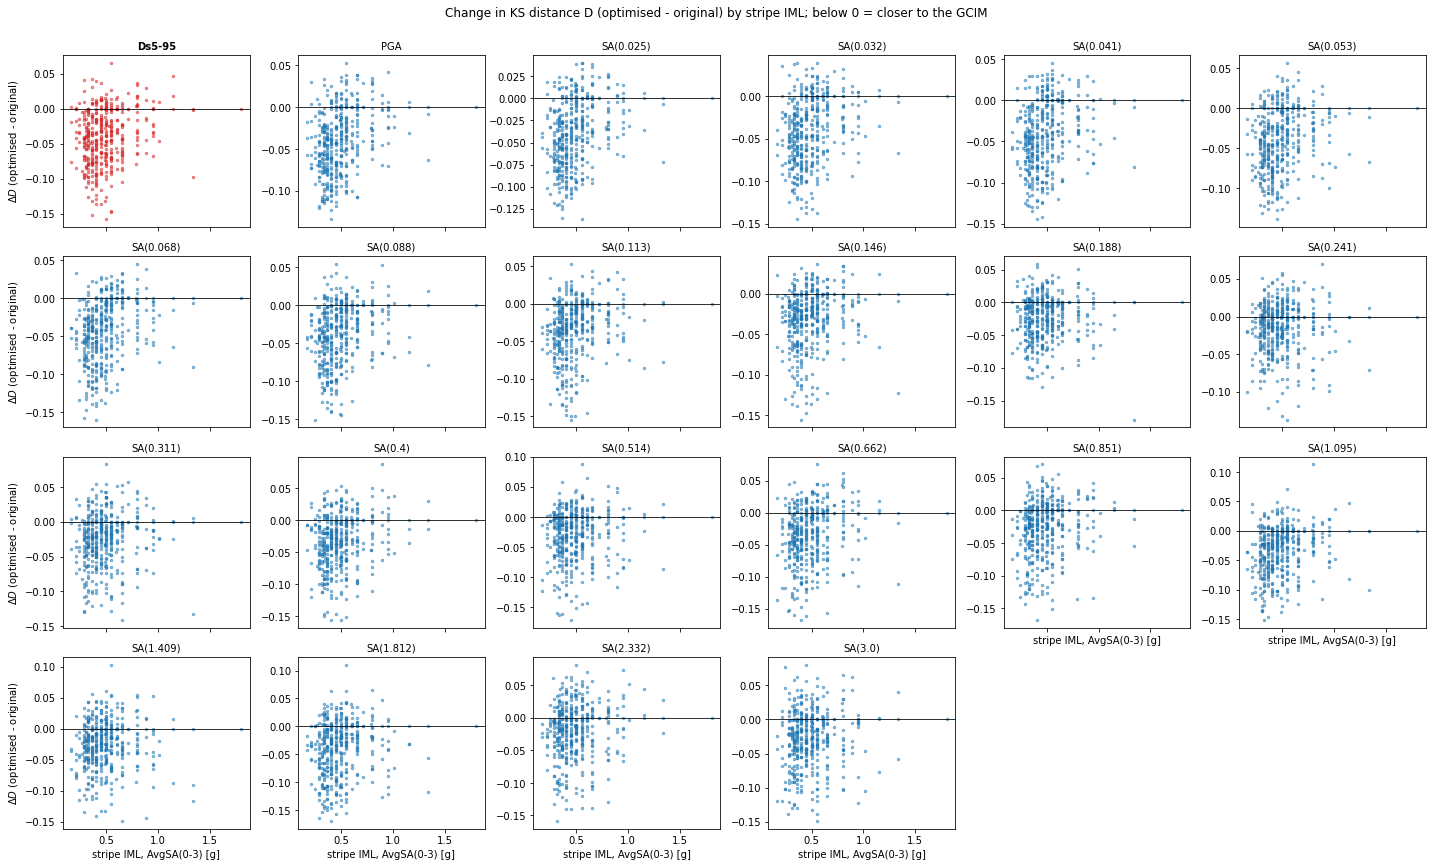

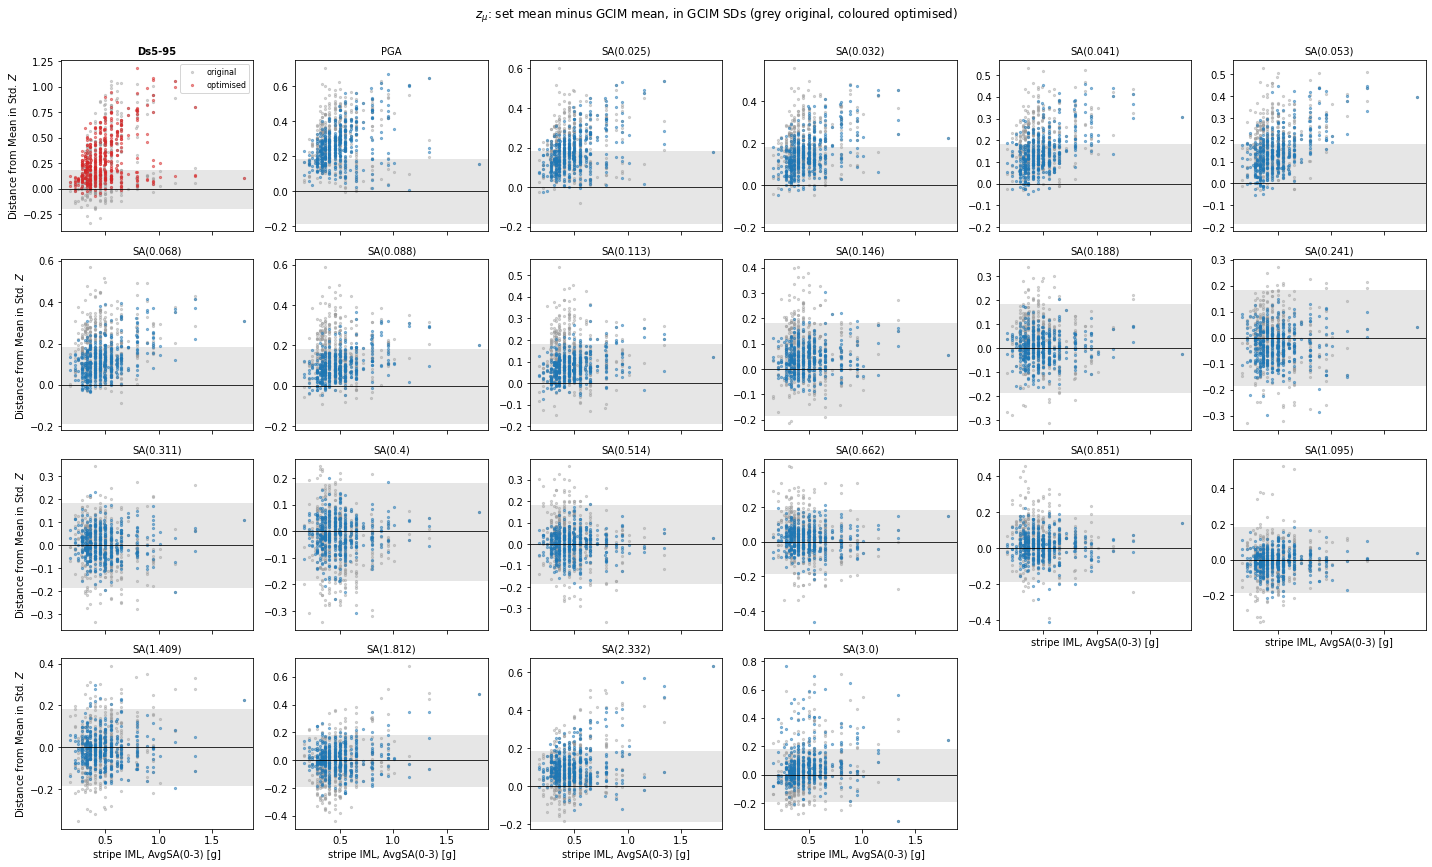

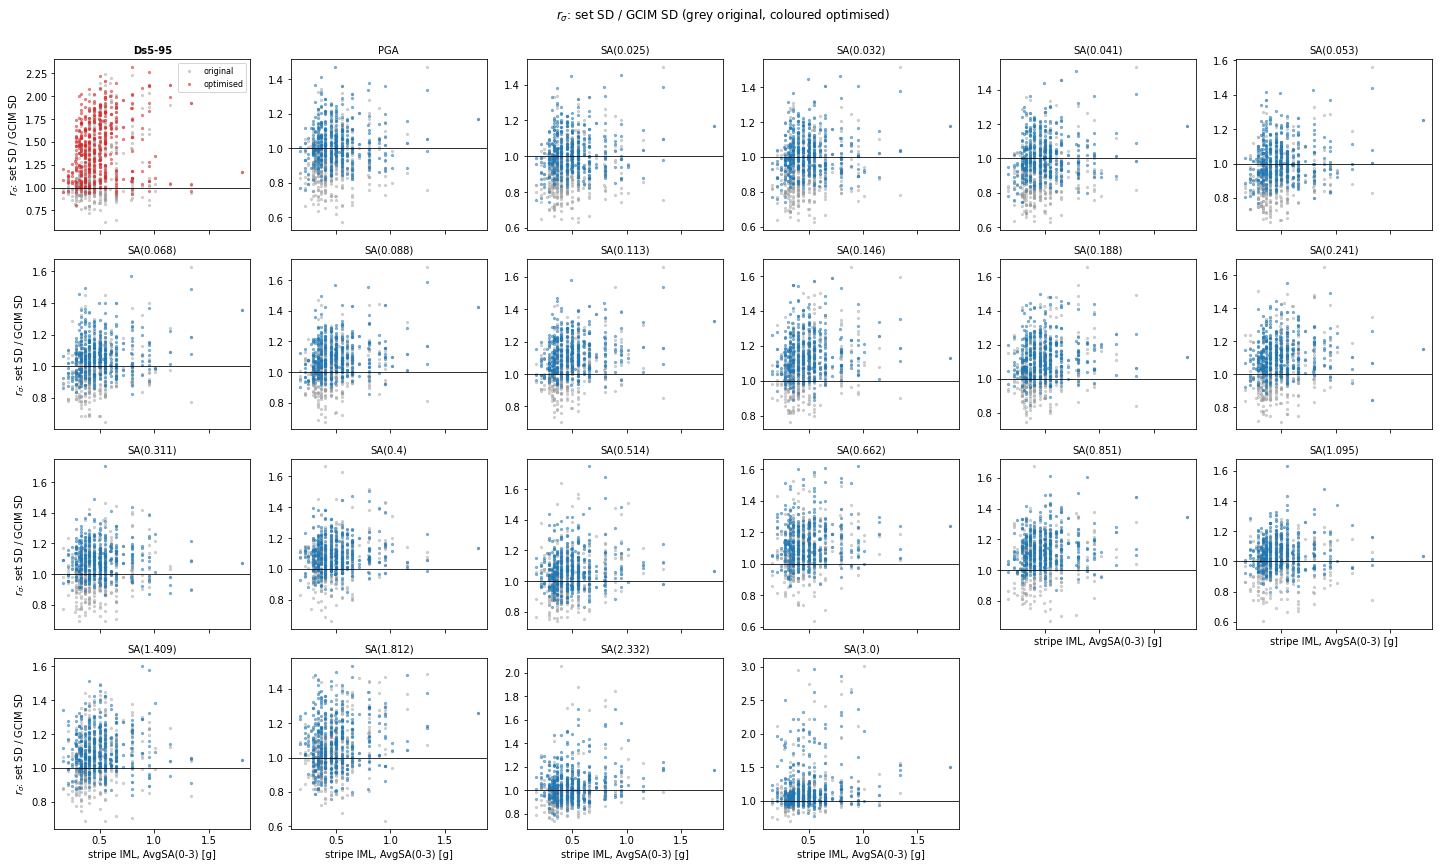

In [49]:
# ---- figures: Delta D, z_mu and r_sigma against IML, one panel per selection IM, Ds5-95 first
c_run = changes[changes.used_in_msa]
ims = rsc.SELECTION_IMS
lab = {im: (rsc.LEAD_IM_LABEL if im == rsc.LEAD_IM else im) for im in ims}


def im_grid(title, sharey=False):
    fig, axs = plt.subplots(4, 6, figsize=(20, 12), sharex=True, sharey=sharey)
    for ax in axs.flat[len(ims):]:
        ax.set_visible(False)
    fig.suptitle(title, y=1.0)
    return fig, axs.flat


fig, axs = im_grid("Change in KS distance D (optimised - original) by stripe IML; below 0 = closer to the GCIM")
for ax, im in zip(axs, ims):
    c = c_run[c_run.im == im]
    ax.scatter(c.iml, c.d_D, s=6, alpha=0.5, color="C3" if im == rsc.LEAD_IM else "C0")
    ax.axhline(0, color="k", lw=0.8)
    ax.set_title(lab[im], fontsize=10, fontweight="bold" if im == rsc.LEAD_IM else None)
for ax in axs[-8:]:
    ax.set_xlabel("stripe IML, AvgSA(0-3) [g]")
for ax in axs[0::6]:
    ax.set_ylabel(r"$\Delta D$ (optimised - original)")
fig.tight_layout()
savefig(fig, "step2_dD_by_iml.png")

for stat, ref, fname, ttl, y_label, in [("z_mu", 0.0, "step2_zmu_by_iml.png", r"$z_\mu$: set mean minus GCIM mean, in GCIM SDs", r"Distance from Mean in Std. $Z$"),
                              ("r_sigma", 1.0, "step2_rsigma_by_iml.png", r"$r_\sigma$: set SD / GCIM SD", r"$r_\sigma$: set SD / GCIM SD")]:
    fig, axs = im_grid(ttl + " (grey original, coloured optimised)")
    for ax, im in zip(axs, ims):
        c = c_run[c_run.im == im]
        ax.scatter(c.iml, c[f"{stat}_orig"], s=5, alpha=0.4, color="0.6", label="original")
        ax.scatter(c.iml, c[f"{stat}_opt"], s=5, alpha=0.5, color="C3" if im == rsc.LEAD_IM else "C0", label="optimised")
        ax.axhline(ref, color="k", lw=0.8)
        if stat == "z_mu":
            # the noise floor of the MEAN: +/- 1/sqrt(30) target SDs
            ax.axhspan(-1 / np.sqrt(30), 1 / np.sqrt(30), color="0.9", zorder=0)
        ax.set_title(lab[im], fontsize=10, fontweight="bold" if im == rsc.LEAD_IM else None)

    for ax in axs[-8:]:
        ax.set_xlabel("stripe IML, AvgSA(0-3) [g]")
    for ax in axs[0::6]:
        ax.set_ylabel(y_label)
    
    list(axs)[0].legend(fontsize=8)
    fig.tight_layout()
    savefig(fig, fname)

### Direction check: do the shifts in the set means all point the same way?

This is the main warning sign. If the optimiser moved, say, the mean duration **up** at most sets,
every affected $a_i$ moves the same way and the shifts **accumulate** in the pooled mean $m_0$ across
120 rows. If the shifts point in random directions, they mostly cancel and only inflate $\tau_u$ slightly.
Reported for each IM over the 437 run sets: the fraction positive, the same weighted by how many
structure-stripes use each set, an exact sign test against ½, and the share within the noise floor.

       im  n_sets  frac_positive  sign_test_p  median_d_mean_ln  mean_d_mean_ln_over_sigma  frac_within_noise  median_d_D  frac_positive_usage_weighted
   RSD595     437         0.6265       0.0000            0.0216                     0.0354             0.7300     -0.0375                        0.6026
      PGA     437         0.3641       0.0000           -0.0167                    -0.0427             0.8970     -0.0408                        0.3510
SA(0.025)     437         0.3783       0.0000           -0.0171                    -0.0415             0.8970     -0.0378                        0.3590
SA(0.032)     437         0.3570       0.0000           -0.0219                    -0.0476             0.8741     -0.0388                        0.3381
SA(0.041)     437         0.3452       0.0000           -0.0222                    -0.0522             0.8673     -0.0424                        0.3301
SA(0.053)     437         0.3428       0.0000           -0.0217                    -0.05

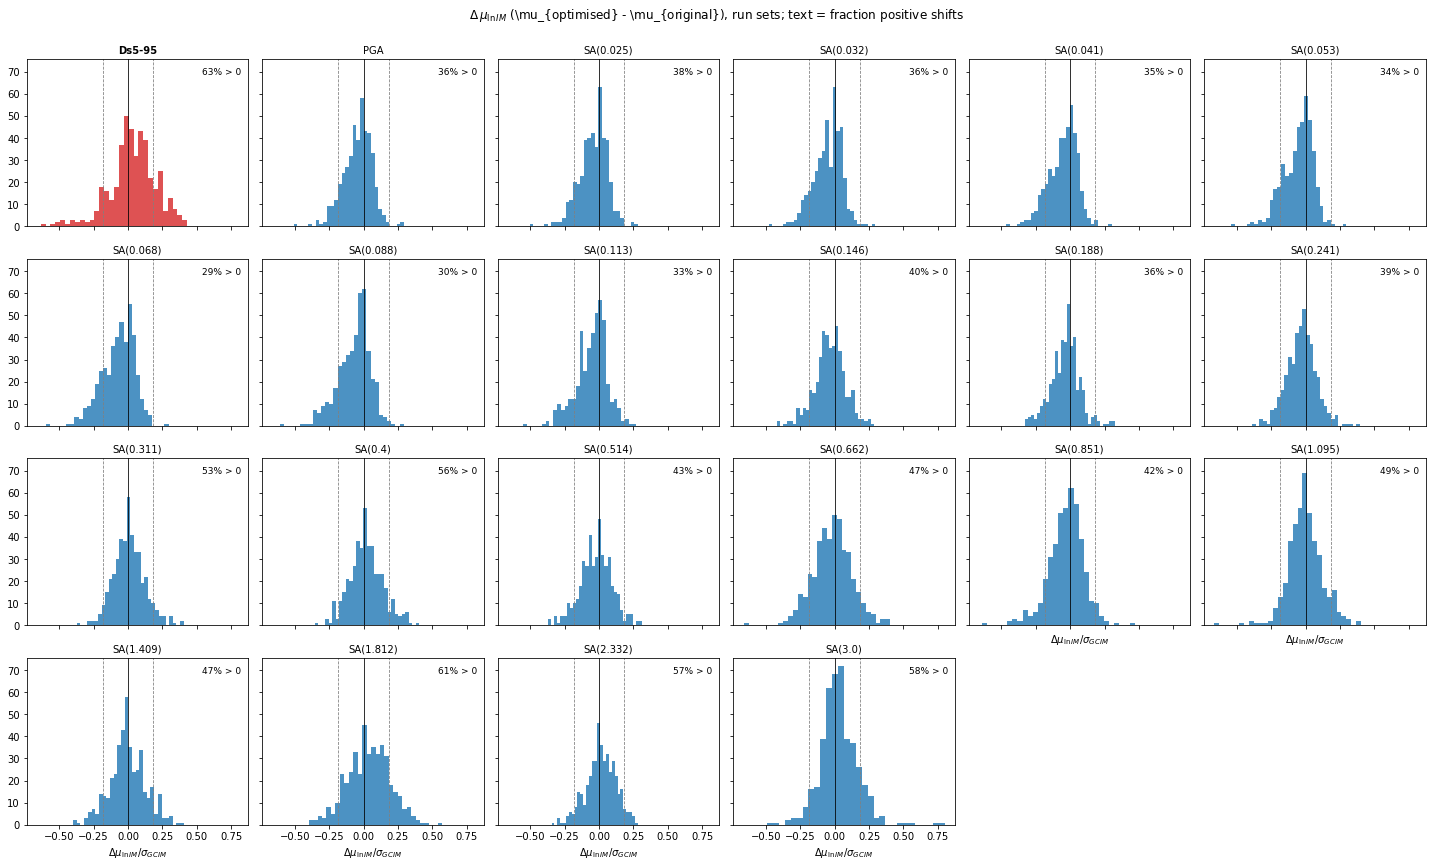

In [50]:
direction = rsc.direction_summary(c_run, uses)
direction.to_csv(OUT / "step2_direction_summary.csv", index=False)
print(direction.round(4).to_string(index=False))

fig, axs = im_grid(r"$\Delta\,\mu_{\ln IM}$ (\mu_{optimised} - \mu_{original}), run sets; text = fraction positive shifts", sharey=True)
for ax, im in zip(axs, ims):
    c = c_run[c_run.im == im]
    x = c.d_mean_ln / c.gcim_sigma            # in target SDs, so the panels share a scale
    ax.hist(x, bins=30, color="C3" if im == rsc.LEAD_IM else "C0", alpha=0.8)
    ax.axvline(0, color="k", lw=0.8)
    for s in (-1, 1):
        ax.axvline(s / np.sqrt(30), color="0.5", ls="--", lw=0.8)   # noise floor
    fp = direction.set_index("im").loc[im, "frac_positive"]
    ax.text(0.97, 0.95, f"{fp:.0%} > 0", transform=ax.transAxes, ha="right", va="top", fontsize=9)
    ax.set_title(lab[im], fontsize=10, fontweight="bold" if im == rsc.LEAD_IM else None)
for ax in axs[-8:]:
    ax.set_xlabel(r"$\Delta\mu_{\ln IM}/\sigma_{GCIM}$")
fig.tight_layout()
savefig(fig, "step2_dmean_histograms.png")
plt.show()

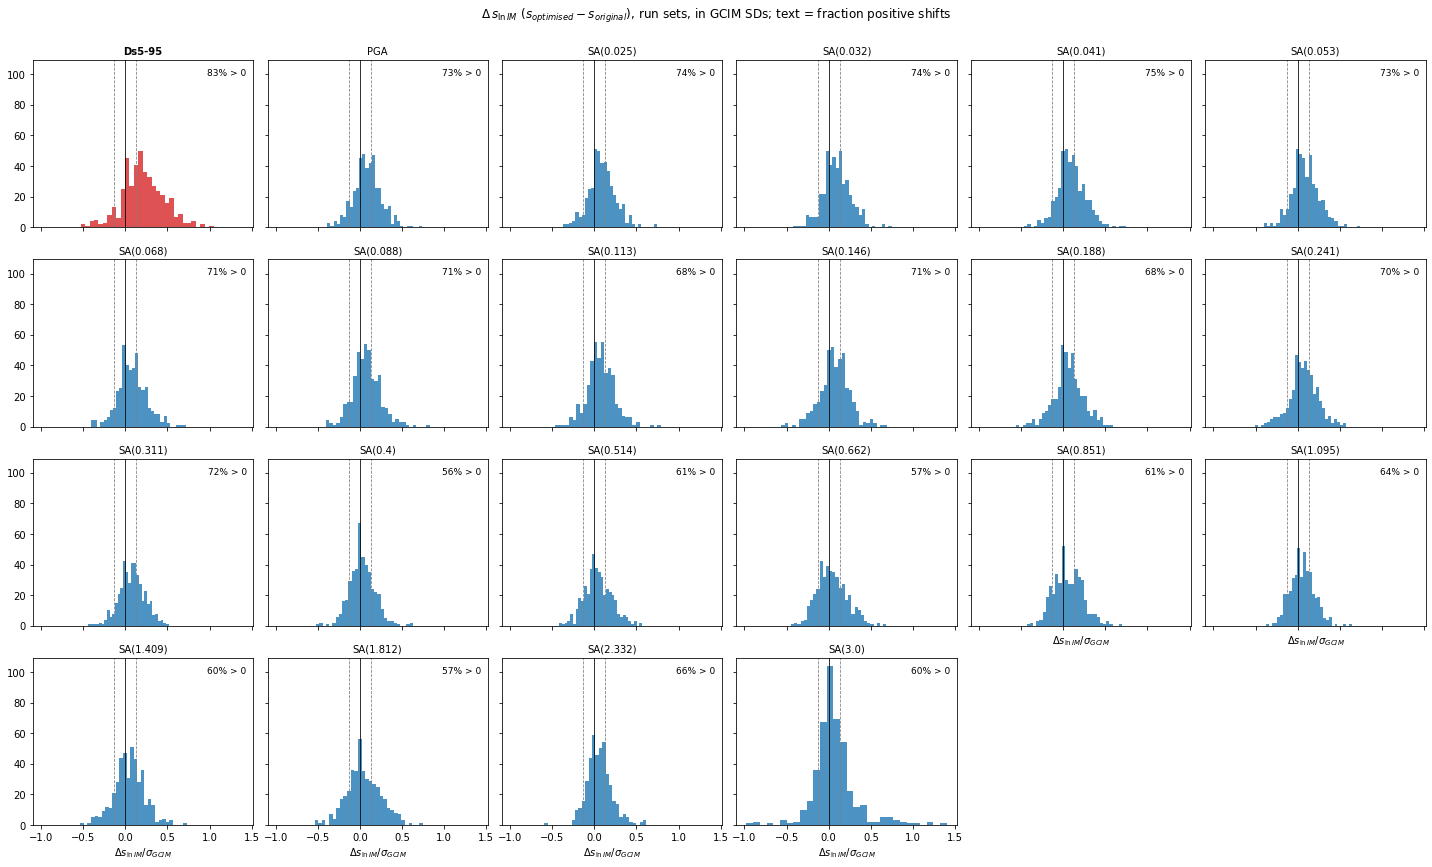

       im  n_sets  frac_positive  sign_test_p  median_d_sd_over_sigma  frac_within_noise
   RSD595     437         0.8274       0.0000                  0.1886             0.2929
      PGA     437         0.7329       0.0000                  0.0910             0.5217
SA(0.025)     437         0.7447       0.0000                  0.0849             0.5561
SA(0.032)     437         0.7400       0.0000                  0.0856             0.5400
SA(0.041)     437         0.7518       0.0000                  0.0841             0.5446
SA(0.053)     437         0.7305       0.0000                  0.0779             0.5378
SA(0.068)     437         0.7069       0.0000                  0.0761             0.5584
SA(0.088)     437         0.7116       0.0000                  0.0752             0.5858
SA(0.113)     437         0.6809       0.0000                  0.0748             0.5767
SA(0.146)     437         0.7139       0.0000                  0.0690             0.5172
SA(0.188)     437    

In [51]:
# ---- the same direction check for the DISPERSION: change in the set SD of ln IM
# (the record set's "beta" for each IM), optimised minus original, in GCIM SDs so the panels
# share a scale. Positive = the optimised set is MORE spread out than the original.
#
# Noise floor for an SD. The SD of 30 independent draws from the target wanders by about
# sigma / sqrt(2 (n - 1)) (normal-theory standard error of a sample SD), i.e.
# 1 / sqrt(58) ~ 0.13 target SDs -- tighter than the floor of a mean, 1 / sqrt(30) ~ 0.18.
sd_floor = 1 / np.sqrt(2 * (rsc.N_RECORDS - 1))

sd_dir = []
fig, axs = im_grid(r"$\Delta\,s_{\ln IM}$ ($s_{optimised} - s_{original}$), run sets, in GCIM SDs; "
                   "text = fraction positive shifts", sharey=True)
for ax, im in zip(axs, ims):
    c = c_run[c_run.im == im]
    x = (c.d_sd_ln / c.gcim_sigma).to_numpy()
    nz = x[x != 0]                                   # unchanged sets carry no sign
    n_pos = int((nz > 0).sum())
    sd_dir.append({"im": im, "n_sets": len(x), "frac_positive": n_pos / max(len(nz), 1),
                   "sign_test_p": stats.binomtest(n_pos, len(nz), 0.5).pvalue if len(nz) else np.nan,
                   "median_d_sd_over_sigma": float(np.median(x)),
                   "frac_within_noise": float(np.mean(np.abs(x) < sd_floor))})
    ax.hist(x, bins=30, color="C3" if im == rsc.LEAD_IM else "C0", alpha=0.8)
    ax.axvline(0, color="k", lw=0.8)
    for s in (-1, 1):
        ax.axvline(s * sd_floor, color="0.5", ls="--", lw=0.8)   # noise floor of an SD
    ax.text(0.97, 0.95, f"{sd_dir[-1]['frac_positive']:.0%} > 0", transform=ax.transAxes,
            ha="right", va="top", fontsize=9)
    ax.set_title(lab[im], fontsize=10, fontweight="bold" if im == rsc.LEAD_IM else None)
for ax in axs[-8:]:
    ax.set_xlabel(r"$\Delta s_{\ln IM}/\sigma_{GCIM}$")
fig.tight_layout()
savefig(fig, "step2_dsd_histograms.png")
plt.show()

sd_dir = pd.DataFrame(sd_dir)
sd_dir.to_csv(OUT / "step2_direction_summary_sd.csv", index=False)
print(sd_dir.round(4).to_string(index=False))


In [52]:
# Trade-off: did a better Ds5-95 fit come at the cost of a worse spectral fit, or the reverse?
trade = rsc.tradeoff_summary(c_run)
trade.to_csv(OUT / "step2_tradeoff.csv")
print("Change in KS distance at each run set (rows: Ds5-95; columns: mean over the 21 spectral IMs)")
print(trade)

Change in KS distance at each run set (rows: Ds5-95; columns: mean over the 21 spectral IMs)
spectral  improved  worsened
ds595                       
improved       320        30
worsened        62        25


### Example stripes, IM by IM

The tables above summarise all 437 run sets. A few stripes make the change concrete. Each figure
shows, for every selection IM, the objects the optimiser compares: the GCIM target CDF, its 95 %
KS band, and the empirical CDFs of the original sets (grey), the **KS-optimised** sets (red, "Opt.
KS") and, for comparison, the **μ/σ-optimised** sets (blue, "Opt. μ/σ": a second scheme that only
matches the mean and SD of each ln IM to the target) and the **KS+μ/σ-optimised** sets (green,
"Opt. KS+μ/σ": a third scheme that minimises a weighted sum of the KS distance and the mean / SD
errors and must still pass KS). The KS distance $D$ of each version is in the corner of each panel,
in that version's colour.

The first three stripes are chosen on the **KS optimisation** (the scheme the rest of this notebook
assesses); the μ/σ and KS+μ/σ sets are drawn there only for reference.

1. **The largest KS-optimisation improvement:** the run set whose objective $J$ fell the most.
2. **The widest KS-optimised Ds5-95 spread:** the run set whose KS-optimised Ds5-95 SD is largest
   relative to the GCIM SD ($r_\sigma$). This shows the heavy duration tail directly.
3. **The best KS-optimised fit:** the run set whose KS-optimised records have the lowest $J$ of all.
4. **Site 43, IML 1.15 g:** a stripe where several of the μ/σ-optimised IMs fail the KS test, i.e.
   matching the mean and SD alone leaves the ECDF outside the 95 % band.
5. **Site 53, IML 1.3368 g:** the only run set whose KS+μ/σ-optimised version fails the KS test.


largest_J_improvement: site 1, IML 0.3600 g | J orig 0.187, Opt. KS 0.086, Opt. mu/sigma 0.110, Opt. KS+mu/sigma 0.092 | Ds5-95 r_sigma 1.26, 1.47, 1.00, 1.04 | 7 of 30 records kept by Opt. KS


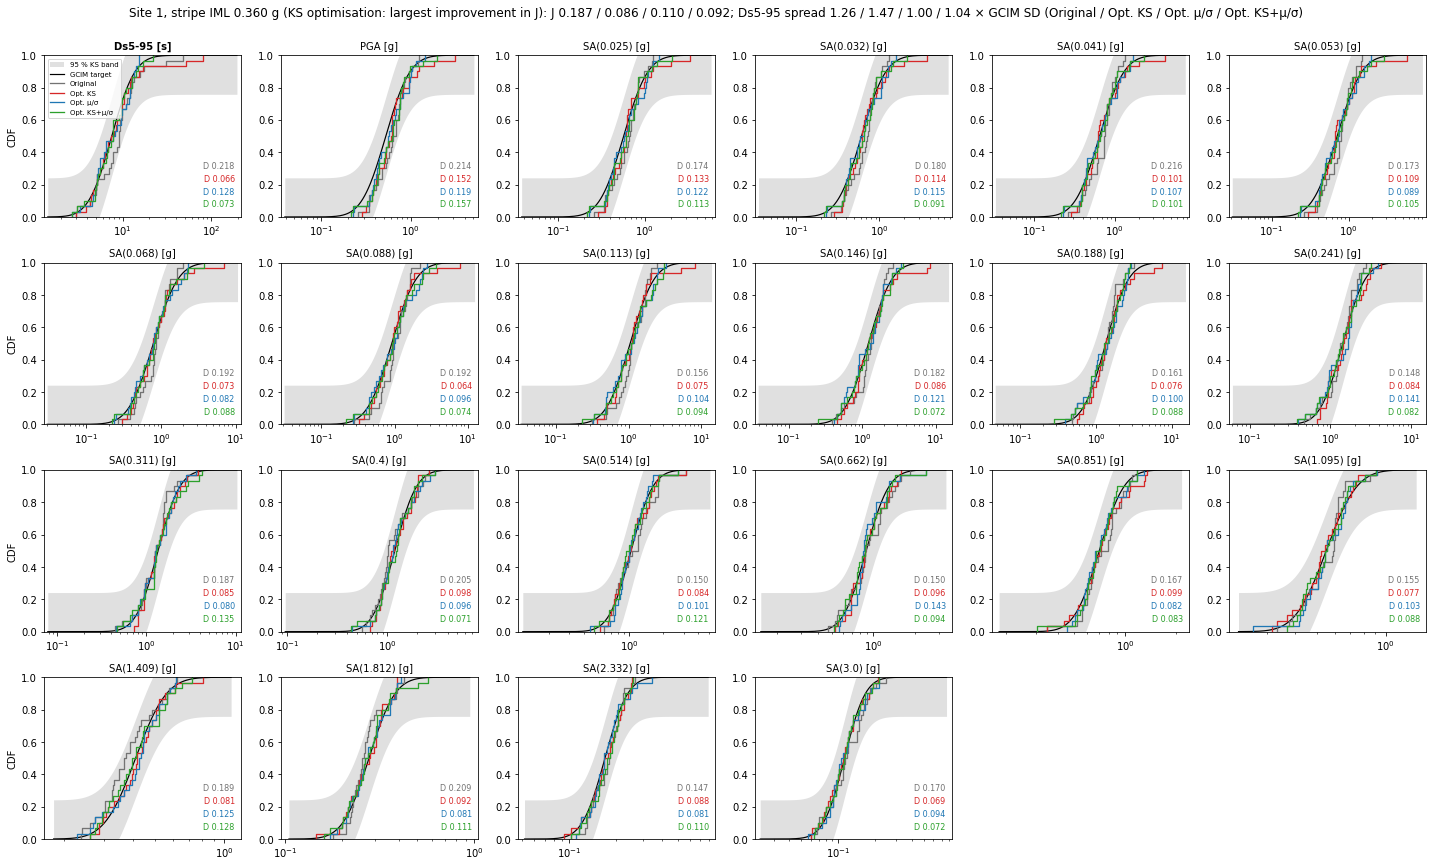

widest_ds595_spread: site 43, IML 0.8000 g | J orig 0.130, Opt. KS 0.132, Opt. mu/sigma 0.152, Opt. KS+mu/sigma 0.141 | Ds5-95 r_sigma 1.92, 2.32, 1.03, 0.98 | 9 of 30 records kept by Opt. KS


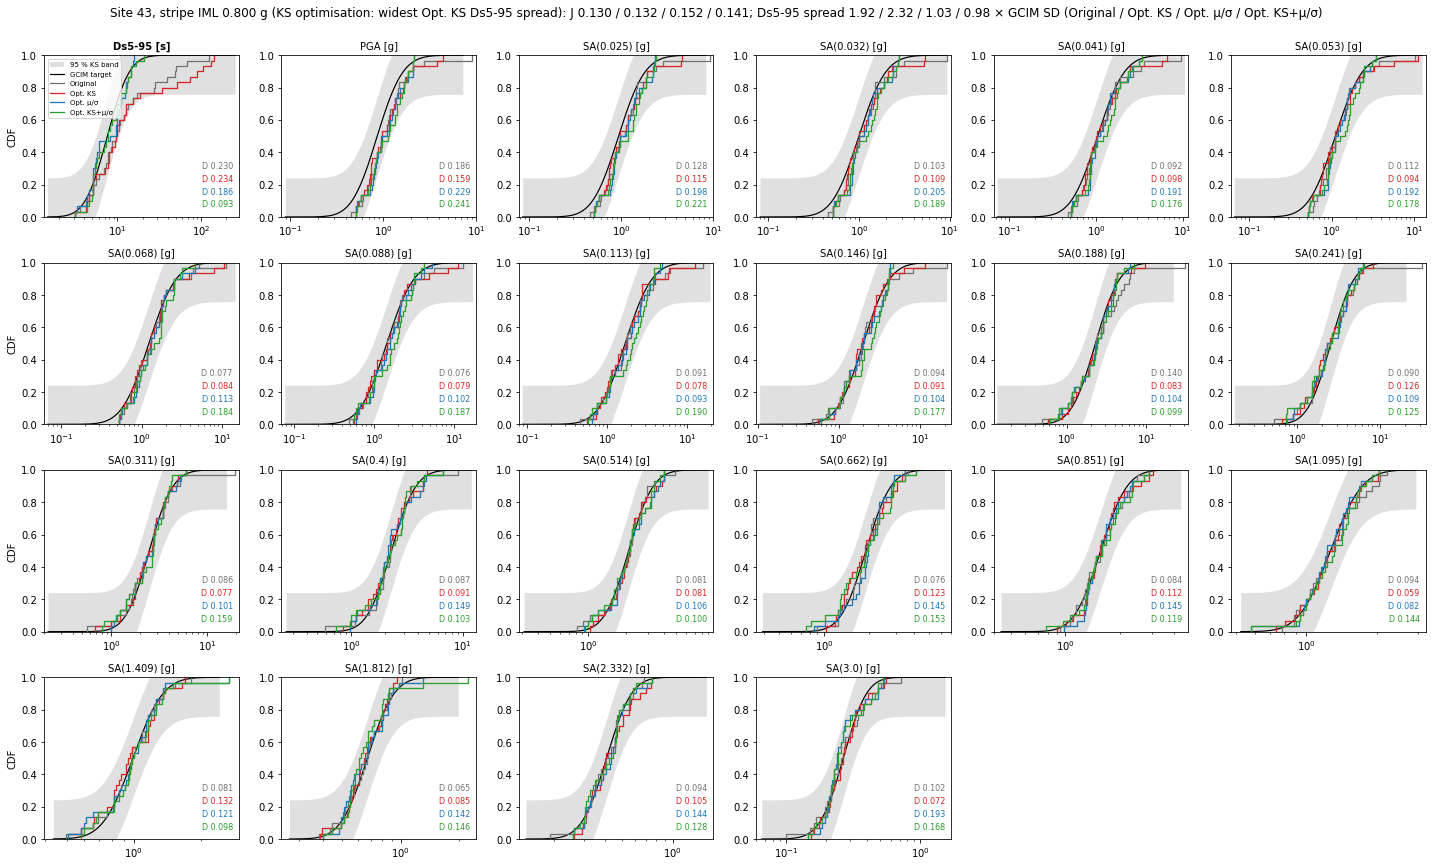

lowest_optimised_J: site 24, IML 0.3600 g | J orig 0.112, Opt. KS 0.070, Opt. mu/sigma 0.113, Opt. KS+mu/sigma 0.074 | Ds5-95 r_sigma 1.00, 1.08, 1.00, 1.01 | 3 of 30 records kept by Opt. KS


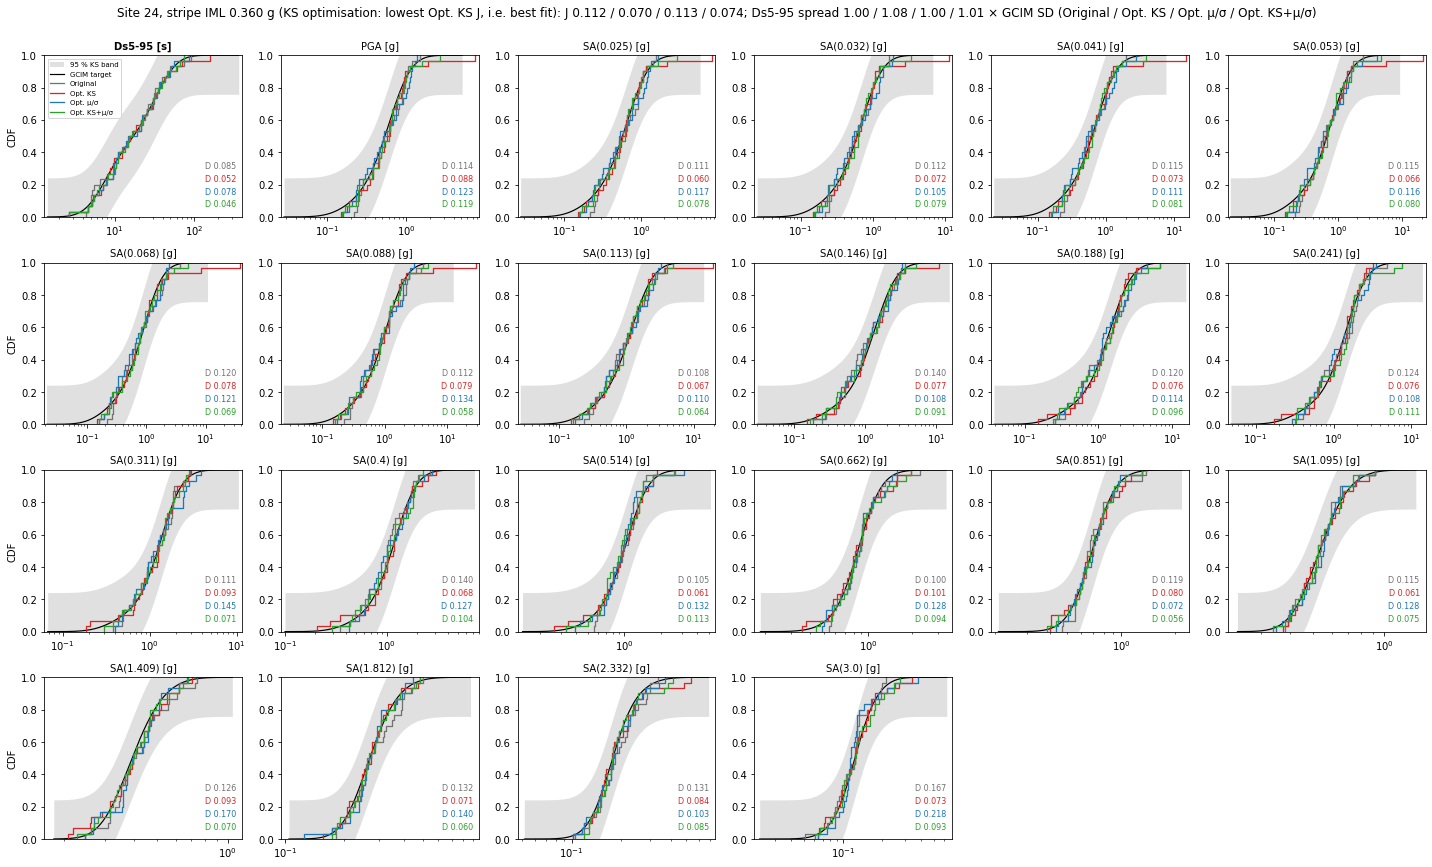

mu_sigma_fails_ks: site 43, IML 1.1500 g | J orig 0.153, Opt. KS 0.153, Opt. mu/sigma 0.324, Opt. KS+mu/sigma 0.099 | Ds5-95 r_sigma 2.13, 2.13, 1.09, 1.02 | 30 of 30 records kept by Opt. KS


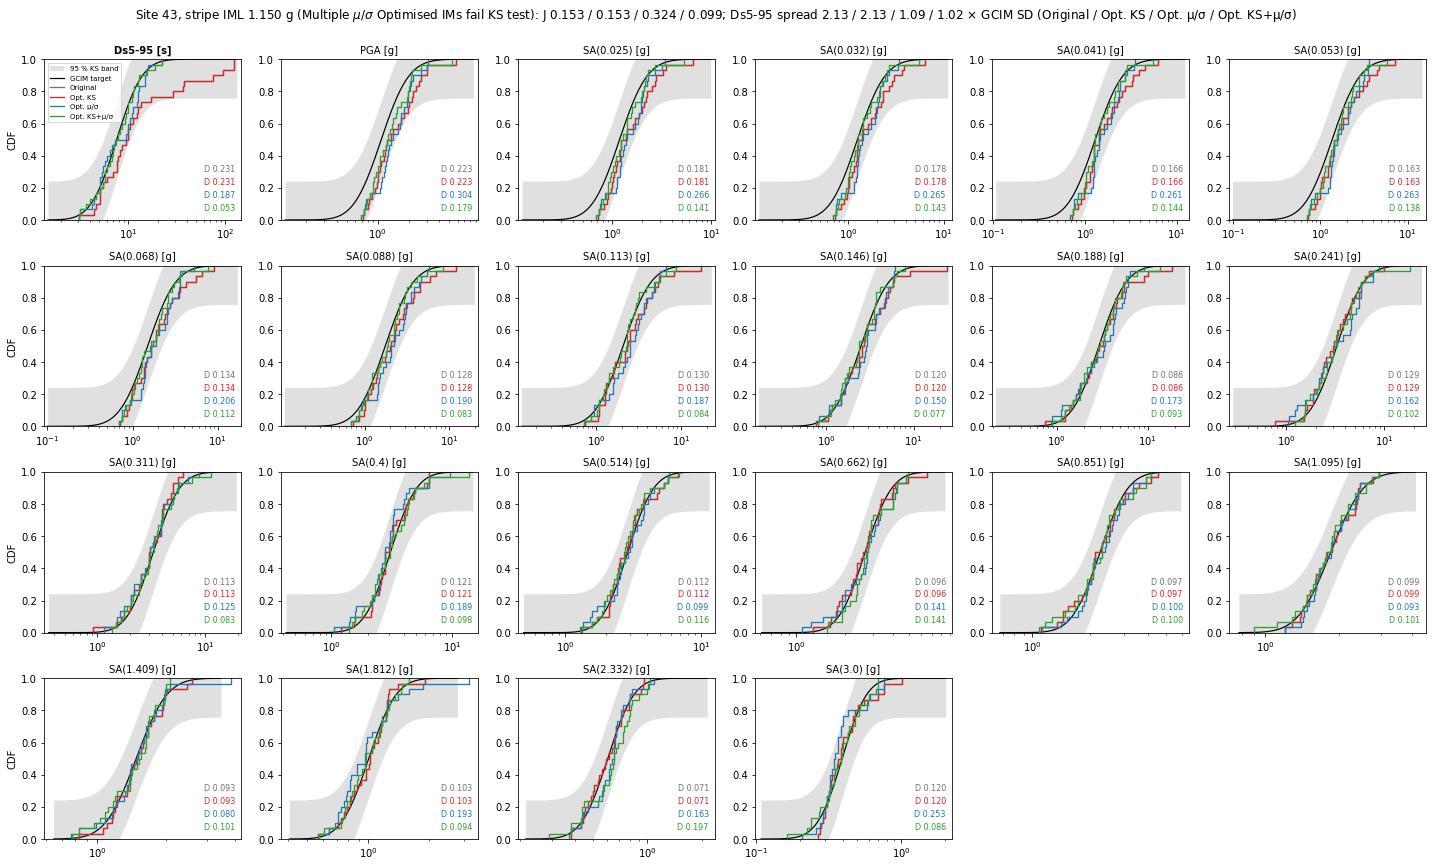

ks_mu_sigma_fails_ks: site 53, IML 1.3368 g | J orig 0.136, Opt. KS 0.136, Opt. mu/sigma 5.846, Opt. KS+mu/sigma 0.126 | Ds5-95 r_sigma 1.93, 1.93, 1.08, 1.08 | 30 of 30 records kept by Opt. KS


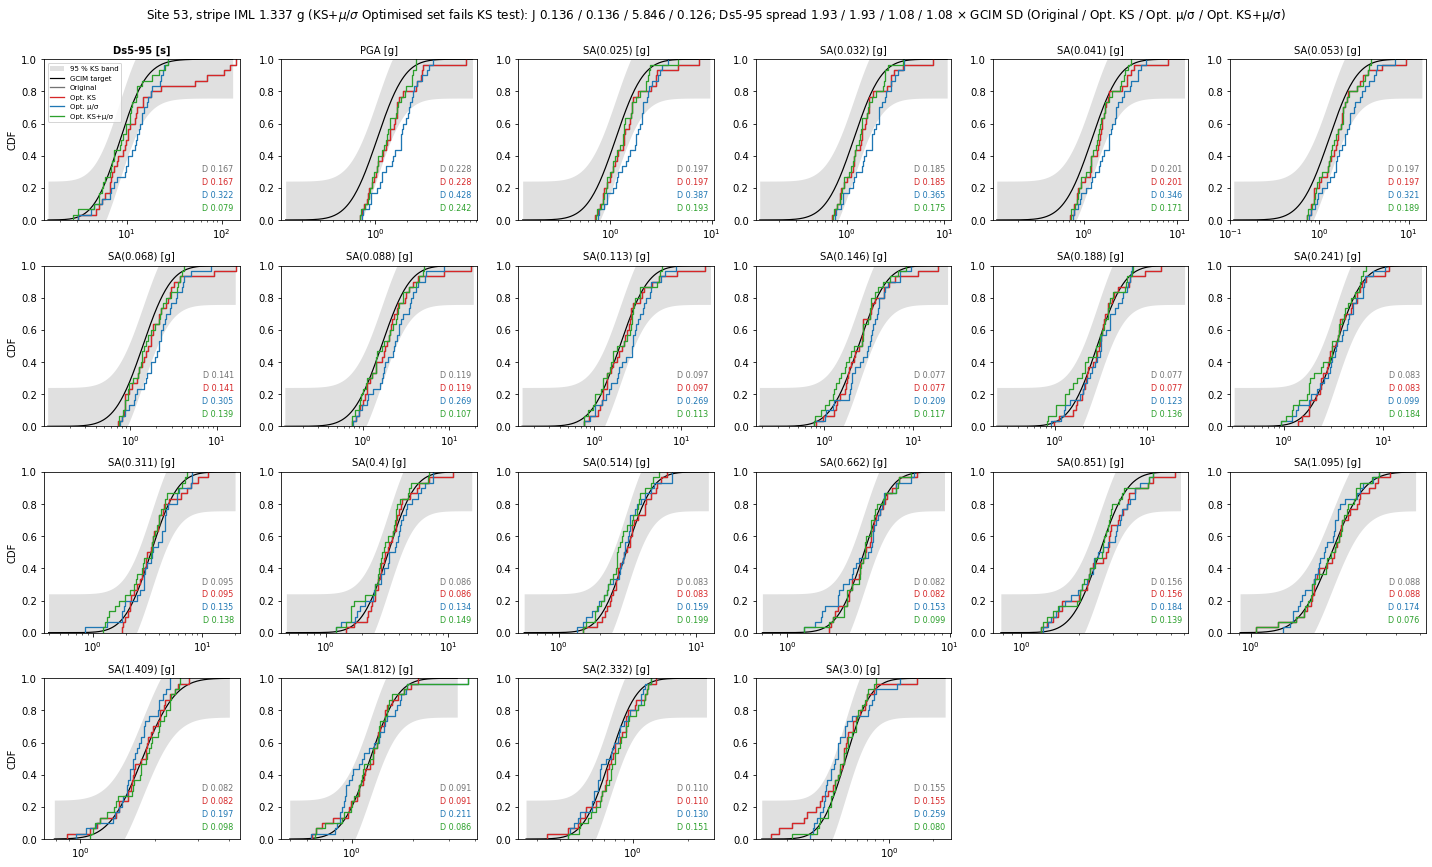

In [53]:
# ---- example stripes: GCIM target, KS band and every version's ECDF for each selection IM
# Examples (1)-(3) are picked on the KS optimisation (the scheme Steps 3-5 assess):
# (1) the run set where the KS optimiser's objective J improved most;
# (2) the run set whose KS-OPTIMISED Ds5-95 spread is widest relative to the GCIM spread;
# (3) the run set whose KS-OPTIMISED records score lowest (best) on the objective J.
# (4) site 43, IML 1.15 g: chosen by hand, a stripe where several mu/sigma-optimised IMs fail
#     the KS test.
# (5) site 53, IML 1.3368 g: the one run set whose KS + mu/sigma-optimised version fails the KS
#     test (asserted below against the selection's own ks_passed flag).
# The mu/sigma-optimised (blue) and KS + mu/sigma-optimised (green) versions of each set are
# drawn for reference in all five.
LABELS = ("Original", "Opt. KS")                   # grey, red
MUS_STYLE = ("C0", "Opt. μ/σ")                     # blue
KMS_STYLE = ("C2", "Opt. KS+μ/σ")                  # green
examples = {      # file tag -> (set key, label for the figure title)
    "largest_J_improvement": (rsc.largest_improvement_key(set_summary),
                              "KS optimisation: largest improvement in J"),
    "widest_ds595_spread": (rsc.widest_lead_dispersion_key(changes, version="opt"),
                            "KS optimisation: widest Opt. KS Ds5-95 spread"),
    "lowest_optimised_J": (rsc.lowest_score_key(set_summary, version="opt"),
                           "KS optimisation: lowest Opt. KS J, i.e. best fit"),
    "mu_sigma_fails_ks": (rsc.match_set_key(43, 1.15, list(orig)),
                          r"Multiple $\mu/\sigma$ Optimised IMs fail KS test"),
    "ks_mu_sigma_fails_ks": (rsc.match_set_key(53, 1.3368, list(orig)),
                             r"KS+$\mu/\sigma$ Optimised set fails KS test"),
}
# example (5) must really be the KS + mu/sigma failure counted in the KS pass table above
assert not kms[examples["ks_mu_sigma_fails_ks"][0]]["ks_passed"], "site 53, 1.3368 g passes KS"
ss = set_summary.set_index(["site", "iml"])
lead = changes[changes.im == rsc.LEAD_IM].set_index(["site", "iml"])

for tag, (key, label) in examples.items():
    # J and Ds5-95 r_sigma of the mu/sigma and KS + mu/sigma versions, computed the same way as
    # for the other two (J is always the KS objective, whatever the scheme optimised)
    J_m = rsc.score_set(mus[key], weights)["J"]
    r_m = rsc.set_moments(mus[key]).set_index("im").loc[rsc.LEAD_IM, "r_sigma"]
    J_k = rsc.score_set(kms[key], weights)["J"]
    r_k = rsc.set_moments(kms[key]).set_index("im").loc[rsc.LEAD_IM, "r_sigma"]
    J_o, J_n = ss.loc[key, ["J_orig", "J_opt"]]
    r_o, r_n = lead.loc[key, ["r_sigma_orig", "r_sigma_opt"]]
    n_kept = int(classes.set_index(["site", "iml"]).loc[key, "n_common"])
    print(f"{tag}: site {key[0]}, IML {key[1]:.4f} g | J orig {J_o:.3f}, Opt. KS {J_n:.3f}, "
          f"Opt. mu/sigma {J_m:.3f}, Opt. KS+mu/sigma {J_k:.3f} | "
          f"Ds5-95 r_sigma {r_o:.2f}, {r_n:.2f}, {r_m:.2f}, {r_k:.2f} | "
          f"{n_kept} of {rsc.N_RECORDS} records kept by Opt. KS")
    title = (f"Site {key[0]}, stripe IML {key[1]:.3f} g ({label}): "
             f"J {J_o:.3f} / {J_n:.3f} / {J_m:.3f} / {J_k:.3f}; Ds5-95 spread "
             f"{r_o:.2f} / {r_n:.2f} / {r_m:.2f} / {r_k:.2f} × GCIM SD "
             f"(Original / Opt. KS / Opt. μ/σ / Opt. KS+μ/σ)")
    fig = rsc.plot_ecdf_grid(orig[key], opt[key], title, labels=LABELS,
                             extra=[(mus[key], *MUS_STYLE), (kms[key], *KMS_STYLE)])
    savefig(fig, f"step2_ecdf_grid_{tag}.png")
    plt.show()


**Step 2 reading.**

* **The objective improved at 91 % of run sets** (median J 0.130 → 0.089).
* **The direction is one-sided.**
  * Mean ln Ds5-95 went **up** at 63 % of sets (p ≈ 2e-7).
  * Short-period SA (≤ 0.24 s) went **down** at 60–70 %.
  * Most individual shifts are inside the noise floor.
* **The Ds5-95 tail got heavier.** The Ds5-95 spread rose to a median 1.44 × σ_GCIM (from 1.10).
  * The longest record per set roughly doubled (median 64 s → 114 s).
  * KS cannot see this: one record moves the empirical CDF by only 1/30.
* **The spread grew for every IM, not just duration** (the dispersion histograms).
  * The set SD of ln IM went up at 83 % of sets for Ds5-95 (median +0.19 σ_GCIM).
  * It went up at 68–75 % for PGA–SA(0.31 s) and at 56–66 % for SA(0.4 s)–SA(3 s).
  * All 22 sign tests reject ½ (p ≤ 0.011). This is more one-sided than the shifts in the means.
  * Wider IM distributions in the records flatten the fragility, which is what Step 4b finds for β.
* **The three example stripes show the range.**
  * Site 1, 0.360 g, the largest improvement: J fell from 0.187 to 0.086 and the Ds5-95 D from
    0.218 to 0.066. Only 7 of 30 records were kept.
  * Site 43, 0.800 g, the widest Ds5-95 spread: the optimised Ds5-95 SD is 2.32 × the GCIM SD
    (1.92 before). J barely moved (0.130 → 0.132), and the Ds5-95 ECDF now runs past 100 s.
  * Site 24, 0.360 g, the best optimised fit: J = 0.070, down from 0.112, with only 3 of 30 records kept. Even here the Ds5-95 SD
    rose slightly (1.00 → 1.08 × GCIM SD), while the mean stayed on target.



### Ds5-95 of each set against its GCIM target

Each point is one run set (one site, one stripe IML). The x-axis is the GCIM target's log-mean
$\mu_{GCIM}$ (top) or log-SD $\sigma_{GCIM}$ (bottom) of $D_{s5-95}$; the y-axis is the same moment of
the set's 30 records, $\overline{\ln D_{s5-95}}_{set}$ or $s_{\ln D_{s5-95},set}$. Columns: original sets
(grey), KS-optimised sets (red), μ/σ-optimised sets (blue) and KS+μ/σ-optimised sets (green). A set that matches its target exactly sits on the black
1:1 line.


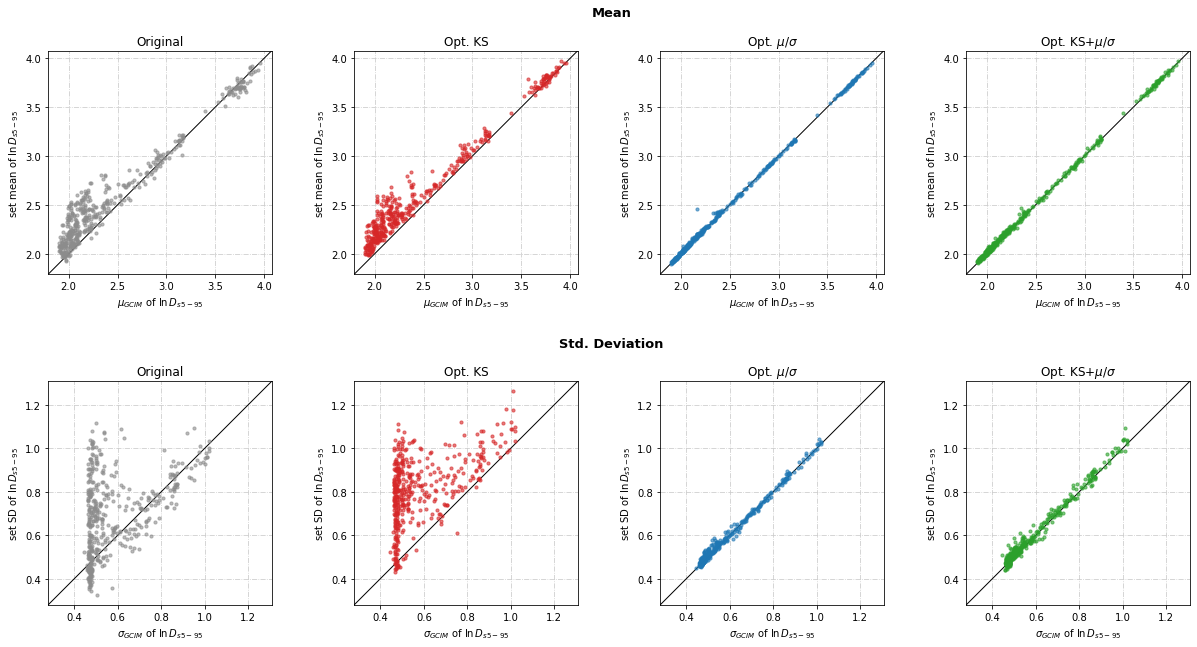

437 run sets per version (orig = Original, opt = Opt. KS, mus = Opt. mu/sigma, kms = Opt. KS+mu/sigma)

Set moment minus GCIM moment (ln Ds5-95):
version           orig       opt       mus       kms
d_mean count  437.0000  437.0000  437.0000  437.0000
       mean     0.1345    0.1553    0.0076    0.0142
       std      0.1461    0.1146    0.0179    0.0164
       min     -0.1584   -0.0319   -0.0182   -0.0420
       25%      0.0251    0.0728   -0.0007    0.0041
       50%      0.1010    0.1237    0.0047    0.0141
       75%      0.2141    0.2203    0.0119    0.0238
       max      0.5135    0.5679    0.2923    0.1121
d_sd   count  437.0000  437.0000  437.0000  437.0000
       mean     0.1164    0.2311    0.0061    0.0118
       std      0.1785    0.1505    0.0117    0.0181
       min     -0.2162   -0.1409   -0.0335   -0.0440
       25%     -0.0275    0.1115   -0.0008    0.0002
       50%      0.0551    0.2327    0.0040    0.0098
       75%      0.2305    0.3410    0.0104    0.0204
      

In [54]:
# ---- Ds5-95 moments of each RUN set against its GCIM target: 2 x 4 scatter.
# Top row: log-mean, bottom row: log-SD. Columns: original, KS-optimised, mu/sigma-optimised,
# KS + mu/sigma-optimised.
# `long` (from score_table) holds, per set, version and selection IM, the set's own moments
# (mean_ln, sd_ln of the 30 records' ln IM, ddof=1) and the GCIM target's (gcim_mu, gcim_sigma).
# The mu/sigma and KS + mu/sigma sets are not in `long`, so their moments come from the same
# function (rsc.set_moments) here. Only sets actually used in an MSA are plotted, as in the rest
# of Step 2.
extra_long = [pd.concat([rsc.set_moments(ens).assign(site=k[0], iml=k[1], version=ver)
                         for k, ens in sets.items()], ignore_index=True)
              for ver, sets in (("mus", mus), ("kms", kms))]
ds_long = pd.concat([long, *extra_long], ignore_index=True)
ds_long = ds_long[ds_long.im == rsc.LEAD_IM].merge(classes[["site", "iml", "used_in_msa"]], on=["site", "iml"])
ds_long = ds_long[ds_long.used_in_msa]

COLS = (("orig", "Original", "0.55"), ("opt", "Opt. KS", "C3"), ("mus", r"Opt. $\mu/\sigma$", "C0"),
        ("kms", r"Opt. KS+$\mu/\sigma$", "C2"))
ROWS = (("Mean", "gcim_mu", "mean_ln", r"$\mu_{GCIM}$ of $\ln D_{s5-95}$", r"set mean of $\ln D_{s5-95}$"),
        ("Std. Deviation", "gcim_sigma", "sd_ln", r"$\sigma_{GCIM}$ of $\ln D_{s5-95}$",
         r"set SD of $\ln D_{s5-95}$"))

# one sub-figure per row, so each row can carry its own super-title
fig = plt.figure(figsize=(17, 9), layout="constrained")
# extra vertical padding: without it each row's super-title touches the middle column's title
fig.get_layout_engine().set(h_pad=0.1, hspace=0.05)
for sub, (row_title, xc, yc, xl, yl) in zip(fig.subfigures(2, 1, hspace=0.04), ROWS):
    sub.suptitle(row_title, fontsize=13, fontweight="bold")
    axs = sub.subplots(1, len(COLS))
    # one common range per row, covering every version, so the columns are directly comparable
    vals = np.concatenate([ds_long[xc], ds_long[yc]])
    pad = 0.05 * (vals.max() - vals.min())
    lim = (vals.min() - pad, vals.max() + pad)
    for ax, (ver, ttl, col) in zip(axs, COLS):
        d = ds_long[ds_long.version == ver]
        ax.scatter(d[xc], d[yc], s=10, alpha=0.6, color=col, zorder=3)
        ax.plot(lim, lim, color="k", lw=1, zorder=2)                     # 1:1 line: set = target
        ax.set_xlim(lim)
        ax.set_ylim(lim)
        ax.set_aspect("equal")
        ax.grid(True, ls="-.", color="0.8", zorder=0)
        ax.set_axisbelow(True)
        ax.set_xlabel(xl)
        ax.set_ylabel(yl)
        ax.set_title(ttl)
savefig(fig, "step2_ds595_set_vs_gcim.png")
plt.show()

# the same comparison in numbers: set moment minus target moment, per version
ds_long = ds_long.assign(d_mean=ds_long.mean_ln - ds_long.gcim_mu, d_sd=ds_long.sd_ln - ds_long.gcim_sigma)
print(f"{ds_long.version.eq('orig').sum()} run sets per version "
      f"(orig = Original, opt = Opt. KS, mus = Opt. mu/sigma, kms = Opt. KS+mu/sigma)\n")
print("Set moment minus GCIM moment (ln Ds5-95):")
print(ds_long.groupby("version")[["d_mean", "d_sd"]].describe().T[["orig", "opt", "mus", "kms"]].round(4).to_string())


### SaRatio(T1) of each set against its GCIM target

The same comparison for $\ln \mathrm{SaRatio}(T_1)$. SaRatio depends on the structure's period, so
here a point is a **structure-stripe** (one site, one structure, one stripe IML), not a record set:
a set run by both the 3- and 5-storey structures gives two points, one at each $T_1$. There are 624
run structure-stripes; 3-storey points are circles, 5-storey points triangles.

* **GCIM side** (x-axis): $\mu_{GCIM}$ and $\sigma_{GCIM}$ of $\ln \mathrm{SaRatio}(T_1)$ at that
  structure's $T_1$, taken from nb 072 (`fragility_regression_stripes_AvgSA_03.csv`). The target is
  the same for every version of a set.
* **Set side** (y-axis): the mean and SD of the 30 records' $\ln \mathrm{SaRatio}(T_1)$, recomputed
  for every version with `rsc.stripe_record_stats` (nb 072's own route: fine-grid spectra,
  $T_j = 0.2T_1 : 0.01 : 3T_1$, geometric mean). **Regression check:** for the original sets it must
  reproduce nb 072's `rec_ln_saratio_mean/sigma` to $10^{-10}$.

SaRatio was never a selection IM, so no optimisation targeted it directly; any change comes
through the 20 SA ordinates the sets were matched on.

**Missing spectra (KS+μ/σ sets only).** Should a KS+μ/σ set contain a record without a fine-grid
spectrum, that structure-stripe is left out of the green column (never computed from part of a
set) and the panel title says how many of the 624 are drawn. With every spectrum computed, all 624
are drawn.


624 structure-stripes x 4 versions in 144 s (2496 distinct set/T1 evaluations)
structure-stripes with every record's spectrum: orig 624/624, opt 624/624, mus 624/624, kms 624/624
original-set SaRatio moments reproduce nb 072 (atol 1e-10)


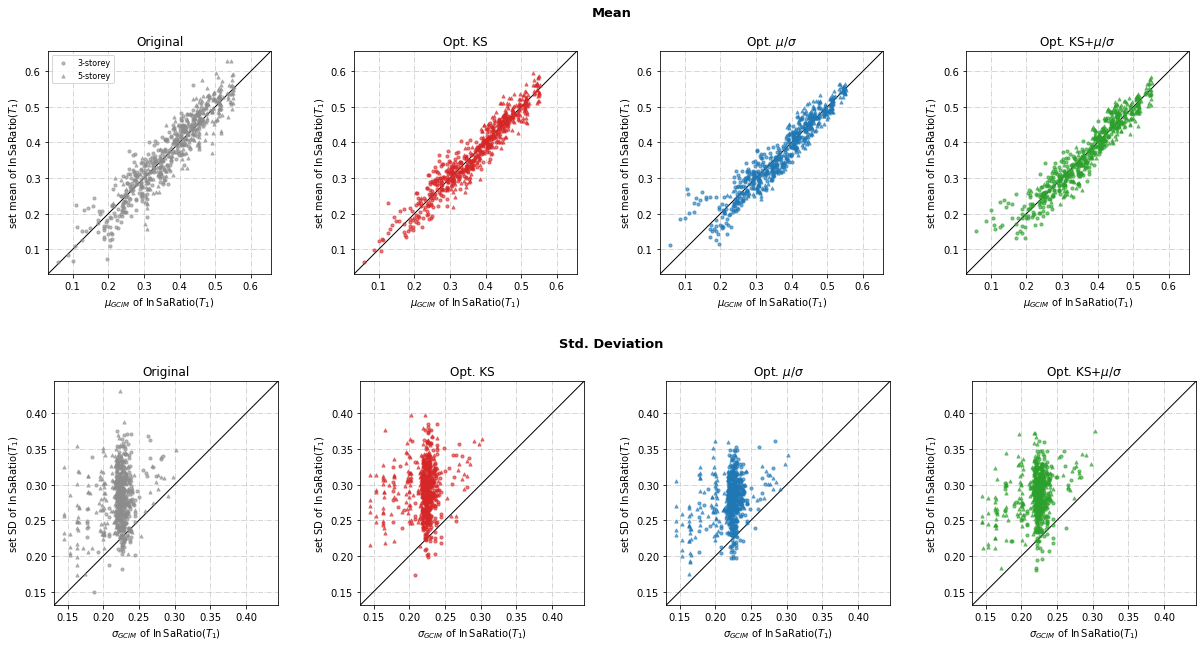


624 run structure-stripes per version (orig = Original, opt = Opt. KS, mus = Opt. mu/sigma, kms = Opt. KS+mu/sigma; kms only where every spectrum exists, see 'count')

Set moment minus GCIM moment (ln SaRatio(T1)):
version           orig       opt       mus       kms
d_mean count  624.0000  624.0000  624.0000  624.0000
       mean     0.0027    0.0009   -0.0004    0.0009
       std      0.0399    0.0291    0.0320    0.0305
       min     -0.1509   -0.0894   -0.0812   -0.0882
       25%     -0.0214   -0.0172   -0.0217   -0.0190
       50%      0.0046    0.0000   -0.0037   -0.0001
       75%      0.0290    0.0202    0.0172    0.0196
       max      0.1215    0.1021    0.1618    0.1093
d_sd   count  624.0000  624.0000  624.0000  624.0000
       mean     0.0605    0.0725    0.0583    0.0649
       std      0.0386    0.0389    0.0314    0.0327
       min     -0.0451   -0.0345   -0.0319   -0.0406
       25%      0.0343    0.0458    0.0381    0.0448
       50%      0.0594    0.0719    0.0586

In [55]:
# ---- ln SaRatio(T1) moments of each RUN structure-stripe against its GCIM target: 2 x 4 scatter.
# Top row: log-mean, bottom row: log-SD. Columns: original, KS-optimised, mu/sigma-optimised,
# KS + mu/sigma-optimised.
# `st072` (section 2's regression-check cell) is nb 072's per-structure-stripe table, merged with
# smap: it has each structure-stripe's record-set key (set_site, set_iml), its T1, the GCIM SaRatio
# moments at that T1, and nb 072's record-side moments for the ORIGINAL sets.
t0 = time.time()
spectra = pd.read_pickle(cfg["proc_data"]["gm_record_spectra"])   # fine-grid PSA, index record_id
VERSIONS = (("orig", orig), ("opt", opt), ("mus", mus), ("kms", kms))
# Versions whose record spectra may still be incomplete: for these ONLY, a set with a record that
# has no fine-grid spectrum gives NaN (and the structure-stripe is left out of that column)
# instead of stopping the notebook. Every other version must be complete, and still raises.
PENDING_SPECTRA = {"kms"}

# Record-side ln SaRatio(T1) moments for every version. A set run by both structures is evaluated
# at each structure's own T1, so results are cached on (version, set key, T1).
_sr_cache = {}


def set_saratio(ver, sets, key, T1):
    """(mean, SD) of ln SaRatio(T1) over the 30 records of `sets[key]`, cached."""
    ck = (ver, key, round(float(T1), 10))
    if ck not in _sr_cache:
        try:
            s = rsc.stripe_record_stats(sets[key], float(T1), spectra)   # KeyError if a spectrum is missing
            _sr_cache[ck] = (s["saratio_mean"], s["saratio_sigma"])
        except KeyError:
            if ver not in PENDING_SPECTRA:
                raise
            _sr_cache[ck] = (np.nan, np.nan)      # spectra pending: never use part of a set
    return _sr_cache[ck]


sr_rows = []
for r in st072.itertuples(index=False):
    key = (int(r.set_site), float(r.set_iml))
    for ver, sets in VERSIONS:
        m, s = set_saratio(ver, sets, key, r.T1)
        sr_rows.append({"site": r.site, "n_storeys": r.n_storeys, "iml": r.iml, "T1": r.T1,
                        "version": ver, "mean_ln": m, "sd_ln": s,
                        "gcim_mu": r.gcim_ln_saratio_mean, "gcim_sigma": r.gcim_ln_saratio_sigma})
sr_long = pd.DataFrame(sr_rows)
print(f"{len(st072)} structure-stripes x {len(VERSIONS)} versions in {time.time() - t0:.0f} s "
      f"({len(_sr_cache)} distinct set/T1 evaluations)")
# how many structure-stripes each version could be computed for (all 624 unless spectra are pending)
n_avail = sr_long.dropna(subset=["mean_ln"]).groupby("version").size().reindex([v for v, _ in VERSIONS],
                                                                                fill_value=0)
print("structure-stripes with every record's spectrum: "
      + ", ".join(f"{v} {n}/{len(st072)}" for v, n in n_avail.items()))

# Regression check: the ORIGINAL sets must reproduce nb 072's record-side moments exactly
o_sr = sr_long[sr_long.version == "orig"]
np.testing.assert_allclose(o_sr[["mean_ln", "sd_ln"]].to_numpy(),
                           st072[["rec_ln_saratio_mean", "rec_ln_saratio_sigma"]].to_numpy(dtype=float),
                           rtol=0, atol=1e-10)
print("original-set SaRatio moments reproduce nb 072 (atol 1e-10)")

COLS_SR = (("orig", "Original", "0.55"), ("opt", "Opt. KS", "C3"), ("mus", r"Opt. $\mu/\sigma$", "C0"),
           ("kms", r"Opt. KS+$\mu/\sigma$", "C2"))
ROWS_SR = (("Mean", "gcim_mu", "mean_ln", r"$\mu_{GCIM}$ of $\ln \mathrm{SaRatio}(T_1)$",
            r"set mean of $\ln \mathrm{SaRatio}(T_1)$"),
           ("Std. Deviation", "gcim_sigma", "sd_ln", r"$\sigma_{GCIM}$ of $\ln \mathrm{SaRatio}(T_1)$",
            r"set SD of $\ln \mathrm{SaRatio}(T_1)$"))
MARKERS = {3: ("o", "3-storey"), 5: ("^", "5-storey")}           # structure type by marker

# one sub-figure per row, so each row can carry its own super-title (as the Ds5-95 figure)
fig = plt.figure(figsize=(17, 9), layout="constrained")
fig.get_layout_engine().set(h_pad=0.1, hspace=0.05)
for sub, (row_title, xc, yc, xl, yl) in zip(fig.subfigures(2, 1, hspace=0.04), ROWS_SR):
    sub.suptitle(row_title, fontsize=13, fontweight="bold")
    axs = sub.subplots(1, len(COLS_SR))
    # one common range per row, covering every version, so the columns are directly comparable
    # (nan-aware: structure-stripes with pending spectra are NaN)
    vals = np.concatenate([sr_long[xc], sr_long[yc]])
    pad = 0.05 * (np.nanmax(vals) - np.nanmin(vals))
    lim = (np.nanmin(vals) - pad, np.nanmax(vals) + pad)
    for ax, (ver, ttl, col) in zip(axs, COLS_SR):
        d = sr_long[sr_long.version == ver].dropna(subset=[yc])
        if len(d) < len(st072):                    # partial column: say how much is drawn
            ttl = f"{ttl}\n({len(d)} of {len(st072)} structure-stripes; spectra pending)"
        for n, (mk, lab_) in MARKERS.items():
            dn = d[d.n_storeys == n]
            ax.scatter(dn[xc], dn[yc], s=10, alpha=0.6, color=col, marker=mk, zorder=3, label=lab_)
        ax.plot(lim, lim, color="k", lw=1, zorder=2)                     # 1:1 line: set = target
        ax.set_xlim(lim)
        ax.set_ylim(lim)
        ax.set_aspect("equal")
        ax.grid(True, ls="-.", color="0.8", zorder=0)
        ax.set_axisbelow(True)
        ax.set_xlabel(xl)
        ax.set_ylabel(yl)
        ax.set_title(ttl)
    if row_title == "Mean":
        axs[0].legend(fontsize=8, loc="upper left")                       # marker key, once
savefig(fig, "step2_saratio_set_vs_gcim.png")
plt.show()

# the same comparison in numbers: set moment minus target moment, per version and structure type
sr_long = sr_long.assign(d_mean=sr_long.mean_ln - sr_long.gcim_mu, d_sd=sr_long.sd_ln - sr_long.gcim_sigma)
sr_long.to_csv(OUT / "step2_saratio_set_vs_gcim.csv", index=False)
print(f"\n{len(o_sr)} run structure-stripes per version (orig = Original, opt = Opt. KS, "
      f"mus = Opt. mu/sigma, kms = Opt. KS+mu/sigma; kms only where every spectrum exists, "
      f"see 'count')\n")
print("Set moment minus GCIM moment (ln SaRatio(T1)):")
print(sr_long.groupby("version")[["d_mean", "d_sd"]].describe().T[["orig", "opt", "mus", "kms"]].round(4).to_string())
print("\nMean gap by structure type:")
print(sr_long.groupby(["n_storeys", "version"])[["d_mean", "d_sd"]].mean().unstack("version")
      .reindex(columns=["orig", "opt", "mus", "kms"], level=1).round(4).to_string())


## 3 — Predicted change in each fragility, without new NLTHA

For each row (one structure at one site), a logistic model for collapse is fitted to the
**existing** per-record outcomes, pooled over the stripes the row's fragility was fitted to:

$$\operatorname{logit}P(C\mid\text{rec}) = \gamma_0 + \gamma_1\ln IML + \gamma_2\ln Ds_{595} + \gamma_3\left[\ln SA(T^*) - \ln IML\right]$$

This is model **M-DS** (plan D3): duration plus one spectral-shape term, $\ln SA(T^*) - \ln IML$,
where $T^*$ is the selection period nearest the structure's $T_1$ (a spectral-shape term, not
SaRatio). It is the only logistic model used in this notebook. Firth's penalised likelihood is used for every row, which keeps estimates finite under separation (plan D2).

Then for each stripe the collapse fraction is **predicted** for both sets, as the mean predicted
probability over each set's 30 records. Predicted is compared with predicted, so model error enters
both and largely cancels. Both sets of predicted fractions are refitted with the same lognormal MLE as
the MSA (on expected counts, see `lognorm_mle_fit_expected`):

$$\Delta a_i = \ln\hat\theta_{i,opt} - \ln\hat\theta_{i,orig},\qquad \Delta\ln\beta_i .$$

**Caveat.** Only differences in the IMs inside the model are captured. Anything else about the new
records (pulse content, frequency content between the 22 ordinates, cumulative measures other than
Ds5-95) is invisible here.

In [56]:
fragilities = mra.load_site_msa_fragilities(FRAG_ROOT, [3, 5], range(60), IM_TAG)
comp = pd.read_csv(STAT_DIR / "fragility_regression_covariate_components_AvgSA_03.csv").set_index(["site", "n_storeys"])

used_keys = sorted(set(zip(smap.set_site, smap.set_iml)))
rec_orig = rsc.records_long(orig, used_keys, "orig")
rec_opt = rsc.records_long(opt, used_keys, "opt")
rec_mus = rsc.records_long(mus, used_keys, "mus")      # mu/sigma-optimised records (Step 3b)
# KS + mu/sigma-optimised records (Step 3b). records_long reads the selection IMs stored in the
# pickles (Ds5-95, SA ordinates), so the logistic predictors need no spectra.
rec_kms = rsc.records_long(kms, used_keys, "kms")
sm = smap.set_index(["site", "n_storeys", "stripe_iml"])

# bootstrap sampling variances of ln theta and ln beta per row -- the row diagnostic's scale
theta = fm.load_fragility_data(BOOT_ROOT, IM_TAG, quantity="theta", verbose=False)
beta = fm.load_fragility_data(BOOT_ROOT, IM_TAG, quantity="beta", verbose=False)
se_a = theta.a.std(axis=1, ddof=1)        # sqrt(v_a[i])
se_lnb = beta.a.std(axis=1, ddof=1)


def row_inputs(site, n, rec_new=None):
    # The row's fitted stripes (the fragility's efc), their record sets, and the training data:
    # the ORIGINAL records with their observed 0/1 collapse flags, slot by slot.
    # `rec_new` is the re-selected record table to predict for: the KS-optimised sets by
    # default, rec_mus / rec_kms for the mu/sigma / KS + mu/sigma-optimised sets (Step 3b).
    rec_new = rec_opt if rec_new is None else rec_new
    imls = np.sort([round(float(v), 6) for v in fragilities[n][site]["efc"][0]])
    keys = [tuple(sm.loc[(site, n, v), ["set_site", "set_iml"]]) for v in imls]

    def pick(R):
        return pd.concat([R[(R.set_site == k[0]) & (R.set_iml == k[1])] for k in keys], ignore_index=True)

    o, p = pick(rec_orig), pick(rec_new)
    train = o.copy()
    train["y"] = np.concatenate([flags.loc[(site, n, v)].to_numpy() for v in imls])
    return imls, train, o, p

In [66]:
t0 = time.time()
rng = np.random.default_rng(SEED)
results, stripe_tabs, draws = [], [], {}
model = rsc.DEFAULT_MODEL          # M-DS, the only logistic model used

for (site, n) in theta.a_hat.index:
    imls, train, o, p = row_inputs(site, n)
    T_star = rsc.nearest_period(comp.loc[(site, n), "T1"])
    # point shift plus N_REPS coefficient draws gamma ~ N(gamma_hat, Cov), which give the
    # uncertainty on Delta a_i that Step 4 propagates through A0c
    r = rsc.row_shift(train, o, p, imls, model, T_star, n_draws=N_REPS, rng=rng)
    draws[(site, n)] = r.pop("d_ln_theta_draws")
    st = r.pop("stripes")
    st.insert(0, "model", model); st.insert(0, "n_storeys", n); st.insert(0, "site", site)
    stripe_tabs.append(st)
    coef = dict(zip(r.pop("coef_names"), r.pop("coef")))
    results.append({"site": site, "n_storeys": n, **r,
                    **{f"coef_{k}": v for k, v in coef.items()},
                    "theta_published": fragilities[n][site]["median"],
                    "beta_published": fragilities[n][site]["dispersion"]})

rows = pd.DataFrame(results)
stripes = pd.concat(stripe_tabs, ignore_index=True)
print(f"Step 3 fitted in {(time.time() - t0) / 60:.1f} min")


Step 3 fitted in 11.0 min


In [67]:
# ---- assemble the per-row table --------------------------------------------------------
rows = rows.set_index(["site", "n_storeys"])
rows["se_a"] = se_a.reindex(rows.index)
rows["se_lnb"] = se_lnb.reindex(rows.index)
rows["d_a_over_se"] = rows["d_ln_theta"] / rows["se_a"]
rows["d_lnb_over_se"] = rows["d_ln_beta"] / rows["se_lnb"]
# calibration: how close the refit on the ORIGINAL predicted fractions sits to the published a_i
rows["calibration_gap"] = np.log(rows["theta_pred_orig"]) - np.log(rows["theta_published"])
rows = rows.reset_index()

D = rows[rows.model == rsc.DEFAULT_MODEL].set_index(["site", "n_storeys"])
dd = pd.DataFrame(draws).T            # (120 rows, N_REPS) draws of Delta a_i (M-DS)
dd.index.names = ["site", "n_storeys"]
D["d_ln_theta_draw_sd"] = dd.std(axis=1, ddof=1).reindex(D.index)
D["d_ln_theta_lo90"] = dd.quantile(0.05, axis=1).reindex(D.index)
D["d_ln_theta_hi90"] = dd.quantile(0.95, axis=1).reindex(D.index)
rows = rows.merge(D[["d_ln_theta_draw_sd", "d_ln_theta_lo90", "d_ln_theta_hi90"]].reset_index(),
                  on=["site", "n_storeys"], how="left")

rows.to_csv(OUT / "step3_row_shifts.csv", index=False)
stripes.to_csv(OUT / "step3_stripe_predictions.csv", index=False)
dd.to_csv(OUT / "step3_delta_a_draws_M-DS.csv")

print("Delta a_i = ln theta_opt - ln theta_orig (M-DS):")
print(rows.groupby("model")[["d_ln_theta", "d_a_over_se", "d_ln_beta", "d_lnb_over_se"]]
          .describe().T.round(4).to_string())
print(f"\nrows with separation flagged: "
      f"{rows[rows.separation].groupby('model').size().to_dict() or 'none'}")
print(f"rows not converged (Firth): {int((~rows.converged).sum())}")
print(f"rows flagged 'extrapolated' (>3 optimised records outside the training range):\n"
      f"{rows.groupby('model').extrapolated.sum().to_dict()}; outside the 99% Mahalanobis ellipse, "
      f"median per row: {rows.groupby('model').n_opt_outside_maha99.median().to_dict()}")
print(f"\ncalibration gap |ln theta_pred_orig - ln theta_published|: median "
      f"{rows.calibration_gap.abs().median():.4f}, max {rows.calibration_gap.abs().max():.4f}")
print(f"M-DS: median |Delta a| {D.d_ln_theta.abs().median():.4f}; "
      f"median draw SD {D.d_ln_theta_draw_sd.median():.4f}")

Delta a_i = ln theta_opt - ln theta_orig (M-DS):
model                    M-DS
d_ln_theta    count  120.0000
              mean    -0.0038
              std      0.0126
              min     -0.0371
              25%     -0.0112
              50%     -0.0030
              75%      0.0029
              max      0.0606
d_a_over_se   count  120.0000
              mean    -0.1495
              std      0.4526
              min     -1.4228
              25%     -0.3947
              50%     -0.1045
              75%      0.1089
              max      1.4416
d_ln_beta     count  120.0000
              mean     0.0358
              std      0.0499
              min     -0.1146
              25%      0.0037
              50%      0.0349
              75%      0.0661
              max      0.1323
d_lnb_over_se count  120.0000
              mean     0.2493
              std      0.3493
              min     -0.8203
              25%      0.0224
              50%      0.2205
              75%    

### 3b — The same prediction for the μ/σ- and KS+μ/σ-optimised record sets

The Step 3 procedure is repeated with the μ/σ-optimised sets, and then with the KS+μ/σ-optimised
sets, in place of the KS-optimised ones. The
logistic models are **the same**: each row's model is trained on the original records and their
observed collapses only, so it does not depend on which re-selected set it then predicts for. Only the
prediction side changes, giving $\Delta a_i^{\mu\sigma} = \ln\hat\theta_{i,\mu\sigma} - \ln\hat\theta_{i,orig}$
(and $\Delta\ln\beta_i^{\mu\sigma}$), and likewise $\Delta a_i^{KS+\mu\sigma}$. No coefficient draws are
taken: these shifts feed only the point fits of Steps 4c/4d, not the propagated-uncertainty check
of Step 4.


In [68]:
# ---- Step 3b: Delta a_i and Delta ln beta_i for the mu/sigma- and KS + mu/sigma-optimised sets


def point_shifts(rec_new):
    """Step 3's per-row point shifts (no coefficient draws) for the re-selected records `rec_new`.

    The logistic model of each row is trained on the ORIGINAL records only, so it is the same
    model whichever re-selected set it then predicts for; only the prediction side changes.
    Returns one row per (site, n_storeys), with the shifts also in units of the bootstrap SE.
    """
    res = []
    for (site, n) in theta.a_hat.index:
        imls, train, o, p = row_inputs(site, n, rec_new=rec_new)
        T_star = rsc.nearest_period(comp.loc[(site, n), "T1"])
        # point shift only (n_draws=0): no rng is used, so the KS results above are untouched
        r = rsc.row_shift(train, o, p, imls, model, T_star)
        r.pop("stripes")
        coef = dict(zip(r.pop("coef_names"), r.pop("coef")))
        # the model must be EXACTLY the one Step 3 fitted for this row; check the coefficients
        r_ks = D.loc[(site, n)]
        assert np.allclose([coef[k] for k in coef], [r_ks[f"coef_{k}"] for k in coef])
        res.append({"site": site, "n_storeys": n, **r})
    out = pd.DataFrame(res).set_index(["site", "n_storeys"])
    out["se_a"] = se_a.reindex(out.index)
    out["se_lnb"] = se_lnb.reindex(out.index)
    out["d_a_over_se"] = out["d_ln_theta"] / out["se_a"]
    out["d_lnb_over_se"] = out["d_ln_beta"] / out["se_lnb"]
    return out


t0 = time.time()
D_mus = point_shifts(rec_mus)                      # same role as D for the KS sets
D_mus.reset_index().to_csv(OUT / "step3b_row_shifts_mu_sigma.csv", index=False)
D_kms = point_shifts(rec_kms)
D_kms.reset_index().to_csv(OUT / "step3b_row_shifts_ks_mu_sigma.csv", index=False)
print(f"Step 3b (mu/sigma and KS + mu/sigma sets) fitted in {(time.time() - t0) / 60:.1f} min\n")

# side by side with the KS-optimised shifts
SHIFTS = (("KS", D), ("mu/sigma", D_mus), ("KS+mu/sigma", D_kms))
cmp3 = pd.DataFrame({f"{lbl}: {q}": Dx[q] for q in ("d_ln_theta", "d_a_over_se", "d_ln_beta")
                     for lbl, Dx in SHIFTS})
print("Per-row predicted shifts, KS- vs mu/sigma- vs KS+mu/sigma-optimised sets (120 rows):")
print(cmp3.describe().T.round(4).to_string())
print()
for lbl, Dx in SHIFTS[1:]:
    print(f"{lbl} rows flagged 'extrapolated': {int(Dx.extrapolated.sum())}; median optimised records "
          f"outside the 99% Mahalanobis ellipse: {Dx.n_opt_outside_maha99.median():.0f}")


Step 3b (mu/sigma and KS + mu/sigma sets) fitted in 0.3 min

Per-row predicted shifts, KS- vs mu/sigma- vs KS+mu/sigma-optimised sets (120 rows):
                          count    mean     std     min     25%     50%     75%     max
KS: d_ln_theta            120.0 -0.0038  0.0126 -0.0371 -0.0112 -0.0030  0.0029  0.0606
mu/sigma: d_ln_theta      120.0  0.0125  0.0183 -0.0315 -0.0000  0.0124  0.0247  0.0552
KS+mu/sigma: d_ln_theta   120.0  0.0108  0.0187 -0.0375  0.0001  0.0113  0.0206  0.0598
KS: d_a_over_se           120.0 -0.1495  0.4526 -1.4228 -0.3947 -0.1045  0.1089  1.4416
mu/sigma: d_a_over_se     120.0  0.5035  0.7008 -1.2069 -0.0007  0.4881  0.9591  2.1431
KS+mu/sigma: d_a_over_se  120.0  0.4454  0.7110 -1.4358  0.0038  0.4074  0.8524  2.1053
KS: d_ln_beta             120.0  0.0358  0.0499 -0.1146  0.0037  0.0349  0.0661  0.1323
mu/sigma: d_ln_beta       120.0 -0.0017  0.0437 -0.1431 -0.0206  0.0016  0.0192  0.1195
KS+mu/sigma: d_ln_beta    120.0  0.0051  0.0523 -0.1404 -0.017

### What one logistic model looks like

**How the models are built.** There is **one logistic model per row**, i.e. per (site, structure)
pair: 120 separate fits, 60 sites × the 3- and 5-storey structures. There is no separate model per
stripe, and no single model shared across rows.

* **Not per stripe.** A stripe has only 30 records and often only a handful of collapses, far too
  few to estimate a slope. The stripe enters **inside** the row's model instead, through the
  predictor $\ln IML$.
* **Not per site.** The 3- and 5-storey structures at a site collapse differently: different
  periods, mechanisms and capacities. Where they ran the same stripe they share the same 30
  records, but their outcomes differ, so each gets its own model.
* **Not one model for all rows.** Collapse capacity is structure-specific, so the intercept and
  the IML slope must be row-specific. A pooled variant with common duration and shape slopes was
  tried earlier and dropped.

**The data behind one model.** These are the row's **fitted stripes**: the stripes its MSA
fragility was fitted to, typically 5, so about 150 runs. Each run is one record at one stripe.
Its outcome is 0 or 1 (collapsed or not), and its predictors are that record's scaled IMs:

$$\operatorname{logit}P(C) = \gamma_0 + \gamma_1 z(\ln IML) + \gamma_2 z(\ln Ds_{5\text{-}95})
  + \gamma_3 z\!\left(\ln SA(T^*) - \ln IML\right),$$

where $z(\cdot)$ standardises with the row's own training mean and SD. The outcomes are treated as
independent Bernoulli trials.

**The uncertainty in the parameters.** The fit is Firth's penalised maximum likelihood (above).
Its covariance is the inverse Fisher information at the estimate,
$\widehat{\mathrm{Cov}}(\hat\gamma) = I(\hat\gamma)^{-1}$. The SEs are the square roots of its
diagonal, and Wald intervals are $\hat\gamma \pm 1.96\,\mathrm{SE}$. This is a large-sample
approximation (Agresti, *Categorical Data Analysis*, 3rd ed., Ch. 5, ~pp. 163–175, approx.). With
~150 runs it is reasonable, but not exact.

The off-diagonal terms matter too. $\ln IML$ and duration are correlated across a row's records, so
their coefficients are estimated jointly and their errors are correlated. That is why the
uncertainty is propagated by drawing whole coefficient vectors $\gamma \sim N(\hat\gamma, I^{-1})$,
not each coefficient separately. Those draws are what Step 3 pushes through to $\Delta a_i$, and what
draws the shaded bands below.

The bands show the uncertainty in the **parameters** only. They do not show the scatter of 0/1
outcomes about the curve, and they do not show model-form error from IMs the model cannot see.

**How to read the figure.**

* **Left: the stripe level.** This is the fragility the MSA estimates. The single row model is
  evaluated at each stripe on that stripe's 30 records and averaged,
  $\hat p = \tfrac{1}{30}\sum_k P(C\mid \text{record } k)$.
  * Crosses: the observed collapse fractions, with the MSA lognormal fit to them (black curve).
  * Grey circles: the predicted fractions for the original records, with 90 % ranges over
    coefficient draws.
  * Red squares: the predicted fractions for the KS-optimised records; blue and green diamonds:
    for the μ/σ- and KS+μ/σ-optimised records (Step 3b).
  * The grey, red, blue and green curves are the lognormal fragilities fitted to those predicted
    fractions, with the same MLE as Step 3. Their medians and dispersions are this row's
    $\theta_{pred}$ and $\beta_{pred}$, so the gap between them **is** $\Delta a_i$ (shift along
    the IML axis) and $\Delta\ln\beta_i$ (change of slope). The panel title gives every record
    set's shifts.
  * The shaded band is the 90 % range of the original-records curve, refitted for 200 coefficient
    draws.
* **Right: the record level, one panel per stripe.** Each point is one record, at its Ds5-95 and
  at 1 (collapsed, red) or 0 (grey), jittered vertically. The curve is P(collapse) against Ds5-95
  at that stripe's IML. The spectral-shape term is held at the stripe's median, so a record with
  unusual spectral shape can sit away from the curve while the full model still fits it.

**The example row** is the one whose Ds5-95 coefficient is the median across all 120 rows, i.e. a
typical fit (site 5, 3-storey; two rows tie exactly, and the lower site number is taken). Change `EXAMPLE` below to look at any other row.


Example row: site 5, 3-storey | T1 0.613 s, T* 0.662 s
150 runs over 5 stripes (0.310, 0.360, 0.400, 0.450, 0.500 g), 83 collapses | Firth converged: True | separation flagged: False

Coefficients (std = per 1 training SD; natural = per unit of the raw predictor):
             coef_std  se_std      z  p_value  ci95_lo_std  ci95_hi_std  coef_natural  se_natural  odds_ratio_x2
intercept       0.342   0.216  1.578    0.114       -0.083        0.766         5.819       1.677            NaN
ln_iml          1.610   0.266  6.059    0.000        1.089        2.131         9.635       1.590        794.937
ln_ds595        0.941   0.282  3.331    0.001        0.387        1.494         1.373       0.412          2.590
shape_Tstar     0.106   0.232  0.459    0.646       -0.348        0.561         0.305       0.665          1.236

Correlation of the coefficient estimates:
             intercept  ln_iml  ln_ds595  shape_Tstar
intercept         1.00    0.11      0.15        -0.04
ln_iml            0

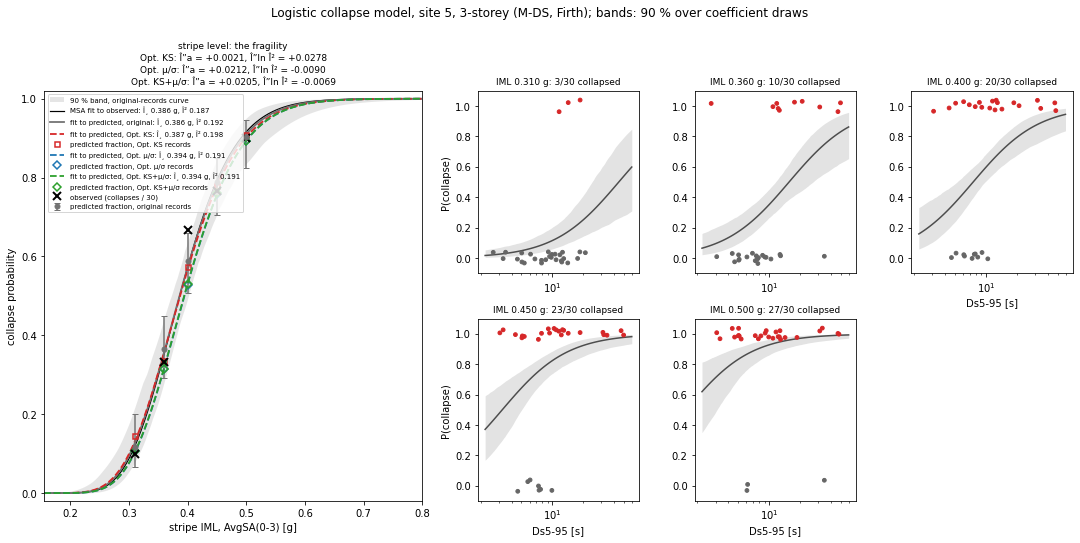

In [69]:
# ---- worked example: one row's logistic model, its parameters and their uncertainty.
# A function, because the same printout and figure are shown for two rows: a typical one
# (here) and the one whose fragility median shifts the most (next cell).


def logit_example(site, n, fname):
    """Refit row (site, n)'s Step 3 model, print its parameters and uncertainty, draw it."""
    imls, train, o, p = row_inputs(site, n)          # the row's fitted stripes and records
    T_star = rsc.nearest_period(comp.loc[(site, n), "T1"])
    lf = rsc.fit_row_logit(train, rsc.DEFAULT_MODEL, T_star)

    # the refit must be the very model Step 3 used for this row
    r_row = rows.set_index(["site", "n_storeys"]).loc[(site, n)]
    assert np.allclose(lf["fit"]["coef"], r_row[[f"coef_{k}" for k in lf["names"]]].to_numpy(float))

    print(f"Example row: site {site}, {n}-storey | T1 {comp.loc[(site, n), 'T1']:.3f} s, T* {T_star} s")
    print(f"{len(lf['y'])} runs over {len(imls)} stripes ({', '.join(f'{v:.3f}' for v in imls)} g), "
          f"{int(lf['y'].sum())} collapses | Firth converged: {lf['fit']['converged']} | "
          f"separation flagged: {lf['sep']['separation']}")

    print("\nCoefficients (std = per 1 training SD; natural = per unit of the raw predictor):")
    print(rsc.logit_coef_table(lf).round(3).to_string())

    # correlations between the coefficient estimates: why whole vectors are drawn, not each alone
    cov = lf["fit"]["cov"]
    corr = cov / np.sqrt(np.outer(np.diag(cov), np.diag(cov)))
    print("\nCorrelation of the coefficient estimates:")
    print(pd.DataFrame(corr, index=lf["names"], columns=lf["names"]).round(2).to_string())

    print("\nTraining mean / SD used to standardise:")
    print(pd.DataFrame({"mean": lf["mu"], "sd": lf["sd"]}).round(3).to_string())

    # how far outside the training data the optimised records sit (extrapolation)
    print(f"\nOptimised records outside the training range: {int(r_row.n_opt_outside_range)} of "
          f"{len(p)}; outside the 99 % Mahalanobis ellipse: {int(r_row.n_opt_outside_maha99)}")
    print(f"What this row gives Step 3: Delta a = {r_row.d_ln_theta:+.4f} "
          f"(90 % from coefficient draws {r_row.d_ln_theta_lo90:+.4f} to {r_row.d_ln_theta_hi90:+.4f}), "
          f"Delta a / SE = {r_row.d_a_over_se:+.2f}, Delta ln beta = {r_row.d_ln_beta:+.4f}")
    # the same row for the mu/sigma-optimised sets (Step 3b, same logistic model)
    r_mus = D_mus.loc[(site, n)]
    p_mus = row_inputs(site, n, rec_new=rec_mus)[3]
    print(f"mu/sigma sets (Step 3b): Delta a = {r_mus.d_ln_theta:+.4f}, "
          f"Delta a / SE = {r_mus.d_a_over_se:+.2f}, Delta ln beta = {r_mus.d_ln_beta:+.4f}; "
          f"outside the training range: {int(r_mus.n_opt_outside_range)} of {len(p_mus)}")
    # ... and for the KS + mu/sigma-optimised sets
    r_kms = D_kms.loc[(site, n)]
    p_kms = row_inputs(site, n, rec_new=rec_kms)[3]
    print(f"KS+mu/sigma sets (Step 3b): Delta a = {r_kms.d_ln_theta:+.4f}, "
          f"Delta a / SE = {r_kms.d_a_over_se:+.2f}, Delta ln beta = {r_kms.d_ln_beta:+.4f}; "
          f"outside the training range: {int(r_kms.n_opt_outside_range)} of {len(p_kms)}")

    fig = rsc.plot_row_logit(lf, train, p, imls,
                             f"Logistic collapse model, site {site}, {n}-storey (M-DS, Firth); "
                             "bands: 90 % over coefficient draws",
                             rng=np.random.default_rng(SEED),
                             # blue / green, as in Step 2
                             extra_recs=[(p_mus, "C0", "Opt. μ/σ"), (p_kms, "C2", "Opt. KS+μ/σ")])
    savefig(fig, fname)
    plt.show()


# Example 1, typical: the row whose (standardised) Ds5-95 coefficient is the MEDIAN over all
# rows. With 120 rows the median lies exactly between the two middle values, so two rows tie;
# rounding the distance and sorting by (distance, site, storeys) breaks the tie the same way
# every run. Set EXAMPLE = (site, n_storeys) to look at any other row.
med = rows.coef_ln_ds595.median()
r_ex = (rows.assign(dist=(rows.coef_ln_ds595 - med).abs().round(9))   # round: float-noise ties
            .sort_values(["dist", "site", "n_storeys"]).iloc[0])
EXAMPLE = (int(r_ex.site), int(r_ex.n_storeys))
logit_example(*EXAMPLE, "step3_logit_example.png")


**Second example: the largest shift.** This is the row whose predicted fragility median moves the
most, i.e. the largest $|\Delta a_i|$ over all 120 rows. It is the extreme case: it shows what the
model does where the optimised records differ most from the original ones. Check how many of the
optimised records sit outside the training range (printed below). A large shift there is partly
the logistic curve being extrapolated.


Example row: site 34, 3-storey | T1 0.333 s, T* 0.311 s
150 runs over 5 stripes (0.550, 0.650, 0.800, 0.950, 1.337 g), 53 collapses | Firth converged: True | separation flagged: False

Coefficients (std = per 1 training SD; natural = per unit of the raw predictor):
             coef_std  se_std      z  p_value  ci95_lo_std  ci95_hi_std  coef_natural  se_natural  odds_ratio_x2
intercept      -1.578   0.363 -4.346    0.000       -2.290       -0.866        -7.828       2.354            NaN
ln_iml          2.942   0.522  5.635    0.000        1.919        3.966         9.551       1.695        750.306
ln_ds595        0.645   0.334  1.933    0.053       -0.009        1.299         1.084       0.561          2.119
shape_Tstar     2.528   0.513  4.930    0.000        1.523        3.533         5.413       1.098         42.604

Correlation of the coefficient estimates:
             intercept  ln_iml  ln_ds595  shape_Tstar
intercept         1.00   -0.61     -0.21        -0.58
ln_iml           -

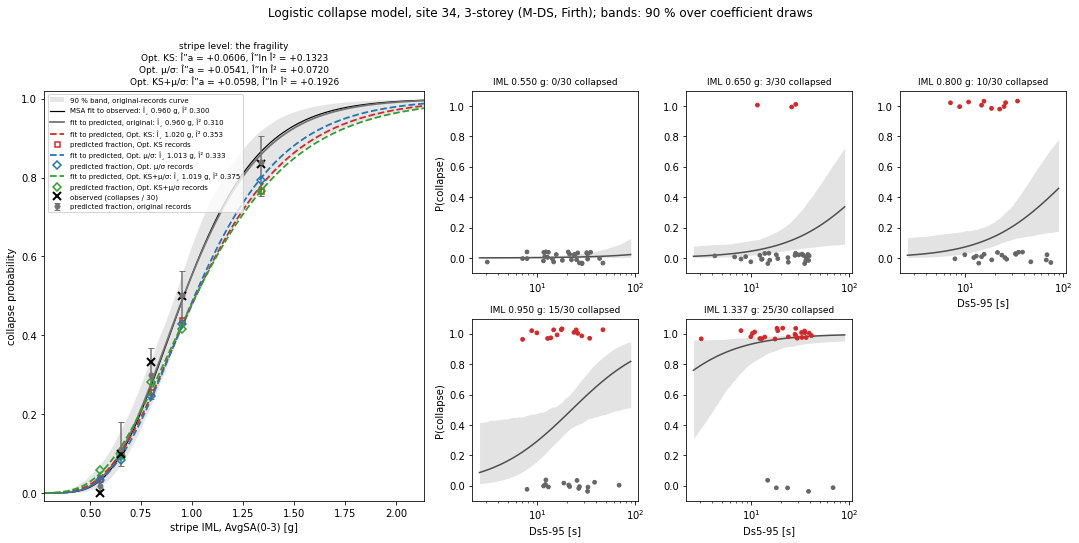

In [70]:
# ---- Example 2, extreme: the row whose fragility median shifts the most (largest |Delta a_i|)
r_big = rows.loc[rows.d_ln_theta.abs().idxmax()]
logit_example(int(r_big.site), int(r_big.n_storeys), "step3_logit_example_largest_shift.png")


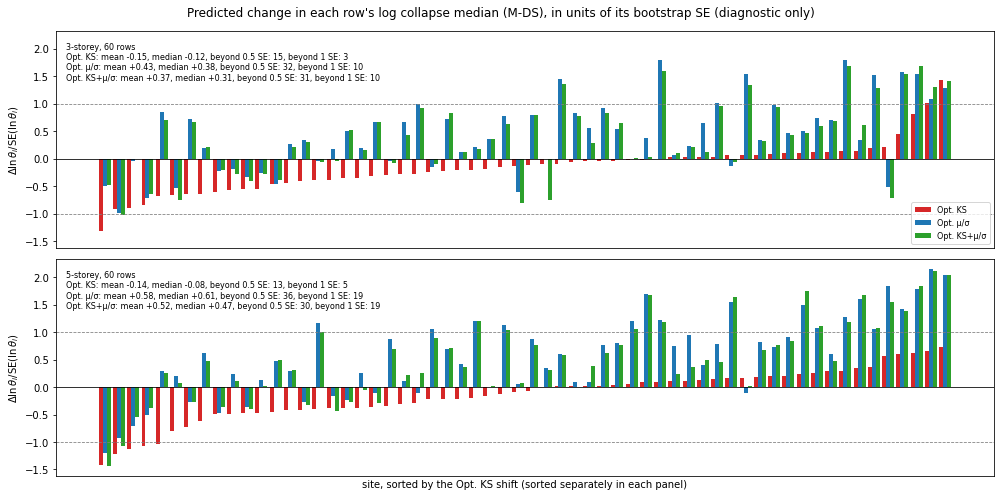

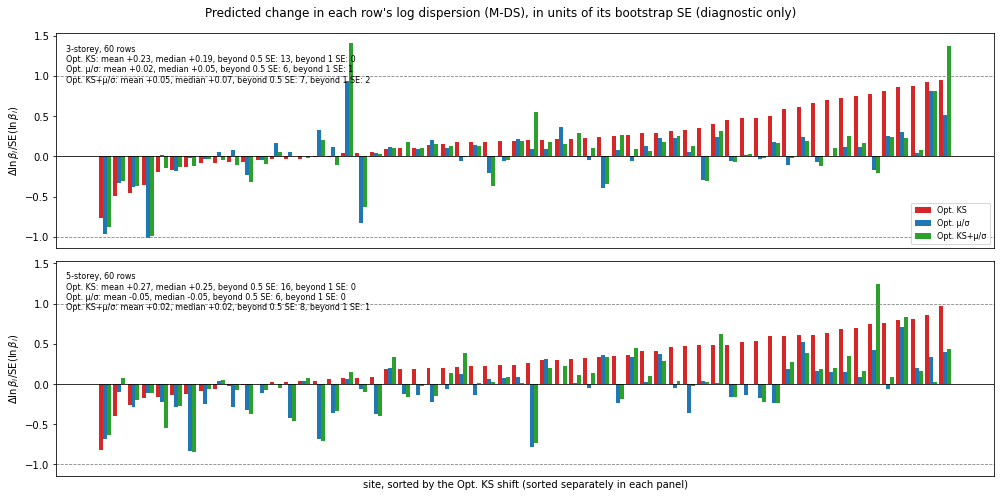

In [71]:
# ---- figures: predicted change per row in units of its bootstrap SE, one figure per
# fragility parameter (theta, beta), one panel per structure type (3s, 5s).
#
# Why split by storey count: the 3s and 5s structures at a site share the site's GCIM, but
# their periods, collapse mechanisms and fitted stripes differ, so the size of the shift can
# differ systematically between them. Pooling both into one sorted bar chart hides that.
#
# Bars = the M-DS logistic model: red = KS-optimised sets (Step 3), blue = mu/sigma-optimised
# and green = KS + mu/sigma-optimised sets (Step 3b), side by side for the same row. Each panel is sorted by its own KS values, so
# the panels are NOT row-aligned with each other (the x position carries no site information).
QUANTITIES = (
    ("d_a_over_se", r"$\Delta \ln\theta_i / \mathrm{SE}(\ln\theta_i)$",
     "log collapse median", "step3_delta_a_over_se_by_row.png"),
    ("d_lnb_over_se", r"$\Delta \ln\beta_i / \mathrm{SE}(\ln\beta_i)$",
     "log dispersion", "step3_delta_lnbeta_over_se_by_row.png"),
)
# (label, colour, bar offset): three bars per row, each 0.28 wide
SETS = (("Opt. KS", "C3", -0.28), ("Opt. μ/σ", "C0", 0.0), ("Opt. KS+μ/σ", "C2", +0.28))

for col, ylabel, what, fname in QUANTITIES:
    # rows: (site, n_storeys); columns: the logistic models
    piv = rows.pivot_table(index=["site", "n_storeys"], columns="model", values=col)
    # one column per record set, both indexed (site, n_storeys)
    both = pd.DataFrame({"Opt. KS": piv[rsc.DEFAULT_MODEL], "Opt. μ/σ": D_mus[col],
                         "Opt. KS+μ/σ": D_kms[col]})
    fig, axs = plt.subplots(2, 1, figsize=(14, 7), sharey=True)
    for ax, n in zip(axs, (3, 5)):
        sub = both.xs(n, level="n_storeys")
        order = sub["Opt. KS"].sort_values().index      # sorted by the KS shift
        x = np.arange(len(order))
        for lab_, colr, off in SETS:
            ax.bar(x + off, sub.loc[order, lab_], color=colr, width=0.28, label=lab_)
        # +/- 1 SE guides: a row past these moves by more than its own sampling noise
        for s in (-1, 1):
            ax.axhline(s, color="0.5", ls="--", lw=0.8)
        ax.axhline(0, color="k", lw=0.8)
        # count of rows beyond 0.5 and 1 SE, for the reading below
        txt = [f"{n}-storey, {len(sub)} rows"]
        for lab_, _, _ in SETS:
            v = sub[lab_]
            txt.append(f"{lab_}: mean {v.mean():+.2f}, median {v.median():+.2f}, beyond 0.5 SE: "
                       f"{int((v.abs() > 0.5).sum())}, beyond 1 SE: {int((v.abs() > 1).sum())}")
        ax.text(0.01, 0.95, "\n".join(txt), transform=ax.transAxes, va="top", fontsize=8)
        ax.set_ylabel(ylabel)
        ax.set_xticks([])
    axs[0].legend(fontsize=8, loc="lower right")
    axs[-1].set_xlabel("site, sorted by the Opt. KS shift (sorted separately in each panel)")
    fig.suptitle(f"Predicted change in each row's {what} (M-DS), in units of its bootstrap SE "
                 "(diagnostic only)")
    fig.tight_layout()
    savefig(fig, fname)
    plt.show()


**Step 3 reading.**

* **Diagnostics are clean.** No separation, and the calibration gap to the published θ is at most 0.7 %.
* **θ:** mean Δa = −0.004, mixed in sign (58 % negative); 8 of 120 rows exceed 1 SE.
* **β** rises about 3.6 % on average, consistent with the heavier duration tail. The rise is
  positive in 77 % of rows, but no row moves by more than 1 SE.
* **The 3s and 5s structures behave alike.** Mean Δa/SE is −0.16 (3s) and −0.14 (5s); mean
  Δlnβ/SE is +0.23 (3s) and +0.27 (5s).
* **Most rows have optimised records outside the training range**, mainly the very long
  durations, so those predictions are extrapolated. **The β rise depends on this.** In the 24 rows
  with at most 3 such records, mean Δlnβ is +0.012. In the 26 rows with the most (13–24), it is
  +0.063.

* **The two worked examples.**
  * Typical row (site 5, 3-storey): Δa = +0.002, Δln β = +0.028. Duration matters (odds ×2.6 per
    doubling); the shape term does not.
  * Largest shift (site 34, 3-storey, T* = 0.31 s): Δa = +0.061 (+1.44 SE), Δln β = +0.132. Here
    the **spectral-shape** term dominates (odds ×43 per doubling of SA(T*)/AvgSA) and duration is
    marginal (p = 0.053). So this row's median moves because the optimised records are weaker
    at the structure's own period, not because of the duration tail. Only 14 of its 150
    optimised records lie outside the training range, so it is not mainly extrapolation.
    The record-level panels plot against Ds5-95 with the shape term held fixed, which is why
    they look loose for this row.

These per-row values are diagnostics only; the study-level comparisons are in Step 4.


## 4 — Study-level test: refit A0c with the shifted SS medians

$a_i^* = a_i + \Delta a_i$ (M-DS logistic model). Everything else is held fixed: the fixed-set arms,
$V_{known}$ (the whole replicate cloud of $a$ is moved by the same constant, which leaves its covariance
unchanged; see `rsc.shift_ss_arm`), the design and site structure.

A0c is fitted once on each container, as **`A0c_hb`**: the hybrid outer bootstrap with $N=200$
replicates. Its point estimates are the ordinary REML fit (identical to `A0c`'s); its replicates
redraw the design, site and row effects as well as the records. So every SE and CI here, including
those of $m_0$, is a **superpopulation** one: other sites and designs could have been drawn. For
$m_0$ that is wider than the record-only ("these 120 rows") SE of `A0c`, so a given shift in $m_0$
counts as fewer SEs.

**Threshold (D1):** each quantity's shift is divided by the original fit's SE and compared with
**0.5 SE**, and each qualitative check is reported as changed or unchanged. This is done for the
θ fit (`A0c_hb`, this step), the β fit (`A0c_bc_hb`, Step 4b) and the θ regression (`A3ab`,
Step 4c).

In [72]:
t0 = time.time()
reg = fm.ModelRegistry(theta, cache_dir=FIT_CACHE, cache_tag=TAG_ORIG)        # original sets
fit_hb = reg.fit(rsc.A0C_HB, n_boot=N_REPS)[0]     # hybrid bootstrap: SEs of m0 and every tau
S0 = rsc.a0c_summary(fit_hb)

delta_a = D["d_ln_theta"]                                  # M-DS, indexed (site, n_storeys)
theta_star = rsc.shift_ss_arm(theta, delta_a)
reg_star = fm.ModelRegistry(theta_star, cache_dir=FIT_CACHE, cache_tag=TAG_KS)  # KS-optimised
fit_hb_s = reg_star.fit(rsc.A0C_HB, n_boot=N_REPS)[0]
S1 = rsc.a0c_summary(fit_hb_s)
print(f"A0c_hb fitted on both containers in {(time.time() - t0) / 60:.1f} min")

shift = rsc.shift_table(S0, S1)
qual = rsc.qualitative_flags(S0, S1)
shift.to_csv(OUT / "step4_model_shifts.csv", index=False)
qual.to_csv(OUT / "step4_qualitative_checks.csv", index=False)
print(shift.round(5).to_string(index=False))
print()
print(qual.to_string(index=False))

[cache] A0c_hb [REML]: loaded (200 saved, using 200)
[cache] A0c_hb [REML]: loaded (200 saved, using 200)
A0c_hb fitted on both containers in 0.3 min
quantity  original  shifted    delta  se_original  delta_over_se  exceeds_threshold  ratio_change
       m   0.00675  0.00333 -0.00342      0.02274       -0.15020              False      -0.00341
   tau_d   0.00689  0.00631 -0.00058      0.00857       -0.06814              False           NaN
   tau_s   0.08363  0.08718  0.00355      0.00761        0.46729              False           NaN
   tau_u   0.01975  0.02197  0.00222      0.00658        0.33739              False           NaN

                         check original shifted  changed
                     sign of m      1.0     1.0    False
            CI of m includes 0     True    True    False
                 tau_d > tau_s    False   False    False
CI of tau_d - tau_s includes 0    False   False    False
                 tau_d at zero    False   False    False
                 

In [73]:
# # ---- check: the fast refit (Cholesky, 1 start; what the bootstrap uses) matches the registry
# fast = rsc.FastA0c(theta)
# f0, f1 = fast.fit(), fast.fit(delta_a)
# for q in ("m", "tau_d", "tau_s", "tau_u"):
#     print(f"{q:6s} registry {S0[q]:+.6f} -> {S1[q]:+.6f} | fast {f0[q]:+.6f} -> {f1[q]:+.6f}")

In [74]:
# # ---- propagate the logistic-model uncertainty: every coefficient draw of Step 3 gives a
# # vector of Delta a_i; refit A0c on each
# t0 = time.time()
# prop = pd.DataFrame([fast.fit(dd[r]) for r in dd.columns]) - pd.Series(f0)
# prop.to_csv(OUT / "step4_propagated_shifts.csv", index=False)
# q = prop.quantile([0.05, 0.5, 0.95]).T
# q.columns = ["p05", "median", "p95"]
# q["se_original"] = [S0[f"se_{k}"] for k in q.index]
# q["p05_over_se"], q["p95_over_se"] = q.p05 / q.se_original, q.p95 / q.se_original
# print(f"{len(prop)} refits in {time.time() - t0:.0f} s")
# print(q.round(5))

In [75]:
# # ---- figure: original vs shifted estimates with +/- 1 SE bars, plus the 0.5-SE band.
# # A function, because the same figure is drawn for theta (here), for beta (Step 4b) and for
# # the A3ab regression on theta (Step 4c, which adds one panel per covariate slope).
# NAMES = {"m": r"$m_0$", "tau_d": r"$\tau_d$", "tau_s": r"$\tau_s$", "tau_u": r"$\tau_u$",
#          # A3ab slopes: per 1 SD of the covariate (build_X centres and scales them)
#          **{k: f"slope on {v}\n(per 1 SD)" for k, v in rsc.COVARIATE_LABELS.items()}}


# def before_after_figure(S_orig, S_shift, title, fname, prop=None, shape=(1, 4), names=None):
#     """One panel per quantity: original fit vs fit on the shifted SS arm.

#     S_orig / S_shift : rsc.a0c_summary / rsc.regression_summary dicts of the two fits. The
#         panels follow S_orig["quantities"]: m and the three taus, then any covariate slopes.
#     prop : optional frame of propagated shifts (one column per quantity, one row per
#         logistic-coefficient draw); if given, its 90 % range is drawn beside the shifted
#         estimate for the quantities it holds. Only A0c on theta has it -- the coefficient
#         draws were propagated through that fit only.
#     shape : (rows, columns) of the panel grid; must hold exactly one panel per quantity.
#     names : optional panel titles overriding NAMES (e.g. what m means in a regression).
#     """
#     quantities = S_orig["quantities"]
#     titles = NAMES | (names or {})
#     nr, nc = shape
#     assert nr * nc == len(quantities), f"{nr}x{nc} grid for {len(quantities)} quantities"
#     fig, axs = plt.subplots(nr, nc, figsize=(3.5 * nc, 3.6 * nr), squeeze=False)
#     for ax, q in zip(axs.ravel(), quantities):
#         se = S_orig[f"se_{q}"]
#         ax.errorbar([0], [S_orig[q]], yerr=[se], fmt="o", color="k", capsize=4, label="original")
#         ax.errorbar([1], [S_shift[q]], yerr=[S_shift[f"se_{q}"]], fmt="s", color="C3", capsize=4,
#                     label="shifted")
#         # the threshold band: a shifted estimate outside it moves by more than 0.5 original SE
#         ax.axhspan(S_orig[q] - rsc.DECISION_THRESHOLD_SE * se, S_orig[q] + rsc.DECISION_THRESHOLD_SE * se,
#                    color="0.85", zorder=0, label="original ± 0.5 SE")
#         if prop is not None and q in prop:
#             lo, hi = prop[q].quantile([0.05, 0.95]).to_numpy() + S_orig[q]
#             ax.vlines(1.15, lo, hi, color="C3", lw=1, ls=":", label="90% from logistic draws")
#         # Delta / SE in the corner, so each panel can be read against the threshold directly
#         # (top centre: the gap between the two error bars, x = 0 and x = 1)
#         ax.text(0.5, 0.97, f"Δ/SE = {(S_shift[q] - S_orig[q]) / se:+.2f}", transform=ax.transAxes,
#                 ha="center", va="top", fontsize=8)
#         ax.set_xlim(-0.6, 1.6)
#         ax.set_xticks([0, 1], ["original", "optimised\n(predicted)"])
#         ax.set_title(titles[q], fontsize=10)
#     axs[0, 0].legend(fontsize=7, loc="lower left")
#     fig.suptitle(title, y=1.03 if nr == 1 else 1.01)
#     fig.tight_layout()
#     savefig(fig, fname)
#     plt.show()


# before_after_figure(S0, S1, "A0c_hb (theta): original record sets vs predicted optimised record sets",
#                     "step4_a0c_before_after.png", prop=prop)


### 4b — Study-level test on β: refit A0c_bc_hb with the shifted SS dispersions

The same test on the dispersion: $\ln\beta_i^* = \ln\beta_i + \Delta\ln\beta_i$ (M-DS, Step 3), with
everything else held fixed, refitted as **`A0c_bc_hb`**. That is the A0c model on the β container,
on bias-corrected estimates (`_bc`) and with the hybrid outer bootstrap (`_hb`). Each arm's
$\ln\beta$ has its own bootstrap bias removed. This matters because the MSA binomial MLE and the IDA
moment fit are biased differently, so the bias does not cancel in the contrast. The shift is
applied to the SS arm's corrected estimate and its whole replicate cloud alike, so the correction
itself is unchanged.

The comparison is the same as in Step 4: each shift is divided by the original fit's SE and
compared with 0.5, and each qualitative check is reported as changed or unchanged. Only the point
shifts are compared. The logistic-coefficient draws of Step 3 were taken for θ only, so
β has no propagated-uncertainty range.


In [76]:
# # ---- beta test (part of D1): A0c_bc_hb on the beta container, original vs shifted SS arm
# t0 = time.time()
# reg_b = fm.ModelRegistry(beta, cache_dir=FIT_CACHE, cache_tag=TAG_ORIG)
# fit_b = reg_b.fit(rsc.A0C_BC_HB, n_boot=N_REPS)[0]
# Sb0 = rsc.a0c_summary(fit_b)

# delta_lnb = D["d_ln_beta"]                                 # M-DS, indexed (site, n_storeys)
# beta_star = rsc.shift_ss_arm(beta, delta_lnb)
# fit_b_s = fm.ModelRegistry(beta_star, cache_dir=FIT_CACHE, cache_tag=TAG_KS).fit(rsc.A0C_BC_HB, n_boot=N_REPS)[0]
# Sb1 = rsc.a0c_summary(fit_b_s)
# print(f"A0c_bc_hb (beta) fitted on both containers in {(time.time() - t0) / 60:.1f} min")

# shift_b = rsc.shift_table(Sb0, Sb1)
# qual_b = rsc.qualitative_flags(Sb0, Sb1)
# shift_b.to_csv(OUT / "step4b_beta_model_shifts.csv", index=False)
# qual_b.to_csv(OUT / "step4b_beta_qualitative_checks.csv", index=False)
# print(shift_b.round(5).to_string(index=False))
# print()
# print(qual_b.to_string(index=False))
# print(f"\nm0 (beta) as a ratio: exp(m0) {np.exp(Sb0['m']):.4f} -> {np.exp(Sb1['m']):.4f}")


In [77]:
# # ---- figure: the same before/after view for beta (no logistic-draw band: theta-only draws)
# before_after_figure(Sb0, Sb1, "A0c_bc_hb (beta): original record sets vs predicted optimised record sets",
#                     "step4b_a0c_bc_hb_beta_before_after.png")


### 4c — Study-level regression on θ: refit A3ab with the shifted SS medians

**A3ab** is A0c with four fixed-effect covariates: the same θ contrast, the same crossed design and
site effects, the same full $V_{known}$:

$$y^{(0)}_{avg,i} = m + \sum_{k=1}^{4} \gamma_k\, x_{k,i} + d_{g[i]} + s_{\sigma[i]} + u_i + \varepsilon_i .$$

The covariates are "site minus FEMA set" differences of GCIM moments, averaged with equal weight
over the stripes each row's fragility was fitted to (nb 072, section 8.0):

| covariate | what it is |
|---|---|
| `d_ln_saratio_mean_unif` | $\Delta E[\ln \mathrm{SaRatio}(T_1)]$ |
| `d_ln_ds595_mean_unif` | $\Delta E[\ln D_{s5-95}]$ |
| `d_ln_saratio_sigma_unif` | $\Delta SD[\ln \mathrm{SaRatio}(T_1)]$ |
| `d_ln_ds595_sigma_unif` | $\Delta SD[\ln D_{s5-95}]$ |

Each covariate is centred and scaled, so $\gamma_k$ is the change in $y$ per 1 SD of the covariate,
and $m$ is the fitted contrast at the covariate **means** (not at zero).

* **What moves.** The covariates describe the GCIM **target**, not the records that were run, so
  they are the same for the original and the optimised sets. Only $y$ moves, by the same
  $\Delta a_i$ as in Step 4 (`theta_star`).
* **What the SEs mean.** `A3ab` is the plain spec, with the **record-only** outer bootstrap
  ($N=200$): records are resampled, the sites and designs are held fixed. Its SEs are therefore
  finite-population ones and are narrower than `A0c_hb`'s superpopulation SEs, so the same shift
  reads as more SEs here than it would in Step 4.
* **θ only.** No β version of A3ab is fitted.
* The qualitative checks are Step 4's, plus, for each slope, its sign and whether its 95 % CI
  includes 0.


In [78]:
# ---- theta regression: A3ab, original vs shifted SS arm (theta only)
# The registries are Step 4's: `reg` holds the original theta container, `reg_star` the one
# with every a_i moved by Delta a_i (rsc.shift_ss_arm, so V_known is unchanged). A3ab's
# covariates are columns of the factor table, which shift_ss_arm leaves untouched.
# overwrite=True: `reg`/`reg_star` were built in an earlier cell, so re-running THIS cell would
# otherwise hit the registry's in-memory 'already fitted' refusal. With the cache the fit is
# then simply reloaded from disk (no refit unless its inputs changed).
t0 = time.time()
fit_r = reg.fit(rsc.A3AB, n_boot=N_REPS, overwrite=True)[0]          # record-only outer bootstrap
Sr0 = rsc.regression_summary(fit_r)
fit_r_s = reg_star.fit(rsc.A3AB, n_boot=N_REPS, overwrite=True)[0]
Sr1 = rsc.regression_summary(fit_r_s)
print(f"A3ab (theta) fitted on both containers in {(time.time() - t0) / 60:.1f} min")

# the covariates really are identical in the two fits (only y moved)
assert all(np.array_equal(fit_r.contrast.rows[k], fit_r_s.contrast.rows[k]) for k in Sr0["slopes"])

print("\nOriginal A3ab coefficients (slopes per 1 SD of the covariate):")
print(fit_r.coef_table().round(4).to_string())

shift_r = rsc.shift_table(Sr0, Sr1)
qual_r = rsc.qualitative_flags(Sr0, Sr1)
shift_r.to_csv(OUT / "step4c_a3ab_model_shifts.csv", index=False)
qual_r.to_csv(OUT / "step4c_a3ab_qualitative_checks.csv", index=False)
print()
print(shift_r.round(5).to_string(index=False))
print()
print(qual_r.to_string(index=False))

# ---- the same A3ab fit for the mu/sigma-optimised sets. A3ab's covariates describe the GCIM
# target, so as for the KS sets only y moves: every a_i by Step 3b's Delta a_i (mu/sigma).
# theta_star_mus is reused in Step 4d, where A3ae's record covariates are swapped in.
t0 = time.time()
theta_star_mus = rsc.shift_ss_arm(theta, D_mus["d_ln_theta"])
reg_mus = fm.ModelRegistry(theta_star_mus, cache_dir=FIT_CACHE, cache_tag=TAG_MUS)
fit_r_m = reg_mus.fit(rsc.A3AB, n_boot=N_REPS)[0]
Sr2 = rsc.regression_summary(fit_r_m)
print(f"\nA3ab (theta) fitted on the mu/sigma container in {(time.time() - t0) / 60:.1f} min")
assert all(np.array_equal(fit_r.contrast.rows[k], fit_r_m.contrast.rows[k]) for k in Sr0["slopes"])

shift_r_m = rsc.shift_table(Sr0, Sr2)
qual_r_m = rsc.qualitative_flags(Sr0, Sr2)
shift_r_m.to_csv(OUT / "step4c_a3ab_mu_sigma_model_shifts.csv", index=False)
qual_r_m.to_csv(OUT / "step4c_a3ab_mu_sigma_qualitative_checks.csv", index=False)
print("\nA3ab, original vs mu/sigma-optimised sets:")
print(shift_r_m.round(5).to_string(index=False))
print()
print(qual_r_m.to_string(index=False))

# ---- and for the KS + mu/sigma-optimised sets, the same way: only y moves, every a_i by Step
# 3b's Delta a_i for those sets. theta_star_kms is reused in Step 4d (record covariates).
t0 = time.time()
theta_star_kms = rsc.shift_ss_arm(theta, D_kms["d_ln_theta"])
reg_kms = fm.ModelRegistry(theta_star_kms, cache_dir=FIT_CACHE, cache_tag=TAG_KMS)
fit_r_k = reg_kms.fit(rsc.A3AB, n_boot=N_REPS)[0]
Sr3 = rsc.regression_summary(fit_r_k)
print(f"\nA3ab (theta) fitted on the KS+mu/sigma container in {(time.time() - t0) / 60:.1f} min")
assert all(np.array_equal(fit_r.contrast.rows[k], fit_r_k.contrast.rows[k]) for k in Sr0["slopes"])

shift_r_k = rsc.shift_table(Sr0, Sr3)
qual_r_k = rsc.qualitative_flags(Sr0, Sr3)
shift_r_k.to_csv(OUT / "step4c_a3ab_ks_mu_sigma_model_shifts.csv", index=False)
qual_r_k.to_csv(OUT / "step4c_a3ab_ks_mu_sigma_qualitative_checks.csv", index=False)
print("\nA3ab, original vs KS+mu/sigma-optimised sets:")
print(shift_r_k.round(5).to_string(index=False))
print()
print(qual_r_k.to_string(index=False))


[cache] A3ab [REML]: loaded (200 saved, using 200)
[cache] A3ab [REML]: loaded (200 saved, using 200)
A3ab (theta) fitted on both containers in 0.0 min

Original A3ab coefficients (slopes per 1 SD of the covariate):
                           beta  se_model  se_sampling  se_boot        z       p   ci_lo   ci_hi
coefficient                                                                                     
intercept               -0.0095    0.0204       0.0177   0.0197  -0.4663  0.6410 -0.0454  0.0327
d_ln_saratio_mean_unif   0.0086    0.0080       0.0052   0.0053   1.0852  0.2778 -0.0036  0.0166
d_ln_ds595_mean_unif    -0.0735    0.0068       0.0032   0.0032 -10.7919  0.0000 -0.0796 -0.0668
d_ln_saratio_sigma_unif  0.0031    0.0064       0.0048   0.0052   0.4880  0.6255 -0.0058  0.0143
d_ln_ds595_sigma_unif   -0.0011    0.0073       0.0037   0.0037  -0.1562  0.8759 -0.0088  0.0054

               quantity  original  shifted    delta  se_original  delta_over_se  exceeds_threshold  rati

In [79]:
# # ---- figure: A3ab before/after, 2 x 4 -- top row m and the taus, bottom row the four slopes
# before_after_figure(Sr0, Sr1, "A3ab (theta): original record sets vs predicted optimised record sets",
#                     "step4c_a3ab_before_after.png", shape=(2, 4),
#                     names={"m": "$m$ (at the covariate means)"})


### 4d — A3ae: the same regression with the records' own covariates, original vs optimised

**A3ae** is A3ab with each covariate replaced by its `_corrected` version (nb 072, section 8.10.6):
the record-set statistic, averaged with equal weight over the row's fitted stripes, minus the FEMA
set's. For the mean duration,

$$x^{rec}_{D,i} = \frac{1}{n_i}\sum_k \overline{\ln D_{s5-95}}_{\text{rec},ik} - \overline{\ln D_{s5-95}}_{\text{FEMA}} .$$

A3ab asks "does the MSA/IDA ratio follow the duration the site's hazard **calls for**?" (GCIM
covariates). A3ae asks "does it follow the duration of the records the MSA **actually ran**?"
(record covariates).

* **What moves.** A3ab's covariates describe the target, so only $y$ moves with the optimised sets.
  A3ae's describe the records, so for the optimised sets **both** move: $y$ by the Step 3
  $\Delta a_i$ (`theta_star`), and the four covariates, recomputed from the optimised records.
* **How the covariates are recomputed.** `rsc.record_covariates` runs nb 072's own route:
  * $\ln D_{s5-95}$ comes from each set's stored IMs.
  * $\ln \mathrm{SaRatio}(T_1) = \ln\big(SA(T_1)/\mathrm{gmean}_j SA(T_j)\big)$, $T_j = 0.2T_1 : 0.01 : 3T_1$,
    comes from each record's fine-grid spectrum (`acc_spectra.pickle`).
  * Each is averaged over the row's fitted stripes, and the FEMA value is subtracted.
  * **Regression check:** on the original sets it must reproduce nb 072's four columns to $10^{-10}$.
* **The optimised container** is `theta_star` with its four `_corrected` columns swapped
  (`rsc.with_covariates`); $V_{known}$ and the replicates are untouched. Both A3ae fits use the
  record-only bootstrap ($N=200$), as A3ab in Step 4c.

**The figure.** Eight lines show the predicted MSA/IDA θ ratio against geometric-mean $D_{s5-95}$:
black = original records, red = KS-optimised ("Opt. KS"), blue = μ/σ-optimised ("Opt. μ/σ") and
green = KS+μ/σ-optimised ("Opt. KS+μ/σ"; for both, $y$ shifted by Step 3b and the record covariates
recomputed from those sets); solid = GCIM covariates (A3ab), dashed = record covariates (A3ae).

* Only the intercept and the mean-duration slope are kept. The covariates are centred, so this is
  the prediction for a row that is average in the other three.
* Each line converts its covariate back to seconds with **its own fit's** centring and scaling.
  The per-SD slopes are not comparable across fits, because the covariate SDs differ. The legend
  therefore gives the slope per unit of $\ln D_{s5-95}$.
* For a GCIM line the x-axis is the target's duration; for a record line it is the duration of
  the records that were run.
* The rugs show where the rows sit: grey = GCIM target (the same for every record set), black =
  original records, red = KS-optimised records, blue = μ/σ-optimised records, green =
  KS+μ/σ-optimised records.


In [80]:
# ---- A3ae: record-side covariates, original vs optimised record sets
t0 = time.time()
# `spectra` (fine-grid PSA, index record_id) was loaded for the SaRatio scatter in section 2
REC_COVS = list(rsc.RECORD_COVARIATES)                             # A3ae's four covariate columns
rows_idx = theta.rows.index                                        # the 120 rows, in container order

# (1) Regression check of the covariate route: on the ORIGINAL sets, rsc.record_covariates must
#     reproduce nb 072's four `_unif_corrected` columns (stored in the factor table) to 1e-10.
#     `comp` carries each row's T1 and its design's FEMA statistics.
cov_orig = rsc.record_covariates(orig, smap, fragilities, comp.loc[rows_idx], spectra)
np.testing.assert_allclose(cov_orig.loc[rows_idx, REC_COVS].to_numpy(),
                           theta.rows[REC_COVS].to_numpy(dtype=float), rtol=0, atol=1e-10)
print("record covariates of the original sets reproduce nb 072 (atol 1e-10)")

# (2) Regression check of the fit: A3ae on the original theta. Its point estimates are the plain
#     full-sample REML fit (the bootstrap only supplies SEs), so they must equal nb 073's A3ae to
#     the precision it was reported at: Ds5-95 mean slope -0.08297 per SD, tau_s 0.0302.
DS_COV_E = "d_ln_ds595_mean_unif_corrected"
# `reg` = original theta container, record-only bootstrap. overwrite=True: `reg` was built in
# Step 4, so re-running this cell would otherwise hit the in-memory 'already fitted' refusal;
# with the cache the fit is simply reloaded from disk.
fit_e = reg.fit(rsc.A3AE, n_boot=N_REPS, overwrite=True)[0]
Se0 = rsc.regression_summary(fit_e)
assert abs(Se0[DS_COV_E] - (-0.08297)) < 5e-6, f"A3ae Ds5-95 slope {Se0[DS_COV_E]:.6f} != nb 073"
assert abs(Se0["tau_s"] - 0.0302) < 5e-5, f"A3ae tau_s {Se0['tau_s']:.6f} != nb 073"
print(f"A3ae on the original records matches nb 073: Ds5-95 slope {Se0[DS_COV_E]:+.5f} per SD, "
      f"tau_s {Se0['tau_s']:.4f}")

# (3) The optimised container: Step 4's shifted SS arm (theta_star, y moved by Delta a_i) with
#     the four covariates recomputed from the OPTIMISED records. V_known and the replicates are
#     those of theta_star, i.e. of the original container.
cov_opt = rsc.record_covariates(opt, smap, fragilities, comp.loc[rows_idx], spectra)
theta_star_e = rsc.with_covariates(theta_star, cov_opt)
# Tagged opt_ks like reg_star: the two registries fit different models (A0c_hb / A3ab there,
# A3ae here), so they never write the same file.
fit_e_s = fm.ModelRegistry(theta_star_e, cache_dir=FIT_CACHE, cache_tag=TAG_KS).fit(rsc.A3AE, n_boot=N_REPS)[0]
Se1 = rsc.regression_summary(fit_e_s)
print(f"A3ae fitted on both containers in {(time.time() - t0) / 60:.1f} min")

# how far the optimised records moved each covariate (per row, records minus records)
d_cov = cov_opt[REC_COVS] - cov_orig[REC_COVS]
print("\nChange in each A3ae covariate, optimised minus original records (120 rows):")
print(d_cov.describe().T.round(4).to_string())

print("\nOriginal A3ae coefficients (slopes per 1 SD of the covariate):")
print(fit_e.coef_table().round(5).to_string())
print("\nOptimised A3ae coefficients (slopes per 1 SD of ITS covariates):")
print(fit_e_s.coef_table().round(5).to_string())

# shift table and qualitative checks, as for A3ab in Step 4c. Note: with the covariates changed,
# the two fits' per-SD slopes are per a (slightly) different SD; see the per-unit-ln slopes below.
shift_e = rsc.shift_table(Se0, Se1)
qual_e = rsc.qualitative_flags(Se0, Se1)
shift_e.to_csv(OUT / "step4d_a3ae_model_shifts.csv", index=False)
qual_e.to_csv(OUT / "step4d_a3ae_qualitative_checks.csv", index=False)
print()
print(shift_e.round(5).to_string(index=False))
print()
print(qual_e.to_string(index=False))

# (4) The mu/sigma-optimised container, built the same way: the SS arm shifted by Step 3b's
#     Delta a_i (mu/sigma), and the four record covariates recomputed from the mu/sigma records.
t0 = time.time()
cov_mus = rsc.record_covariates(mus, smap, fragilities, comp.loc[rows_idx], spectra)
# theta_star_mus (SS arm shifted by Step 3b) was built for A3ab in Step 4c. Tagged opt_mu_sig
# like reg_mus: A3ab there, A3ae here, so the two registries never write the same file.
theta_star_mus_e = rsc.with_covariates(theta_star_mus, cov_mus)
fit_e_m = fm.ModelRegistry(theta_star_mus_e, cache_dir=FIT_CACHE, cache_tag=TAG_MUS).fit(
    rsc.A3AE, n_boot=N_REPS)[0]
Se2 = rsc.regression_summary(fit_e_m)
print(f"\nA3ae fitted on the mu/sigma container in {(time.time() - t0) / 60:.1f} min")

d_cov_m = cov_mus[REC_COVS] - cov_orig[REC_COVS]
print("\nChange in each A3ae covariate, mu/sigma-optimised minus original records (120 rows):")
print(d_cov_m.describe().T.round(4).to_string())
print("\nmu/sigma A3ae coefficients (slopes per 1 SD of ITS covariates):")
print(fit_e_m.coef_table().round(5).to_string())

shift_e_m = rsc.shift_table(Se0, Se2)
qual_e_m = rsc.qualitative_flags(Se0, Se2)
shift_e_m.to_csv(OUT / "step4d_a3ae_mu_sigma_model_shifts.csv", index=False)
qual_e_m.to_csv(OUT / "step4d_a3ae_mu_sigma_qualitative_checks.csv", index=False)
print()
print(shift_e_m.round(5).to_string(index=False))
print()
print(qual_e_m.to_string(index=False))

# (5) The KS + mu/sigma-optimised container, built the same way: the SS arm shifted by Step 3b's
#     Delta a_i for those sets (theta_star_kms, Step 4c), and the four record covariates
#     recomputed from the KS + mu/sigma records. Tagged opt_ks_mu_sig like reg_kms (A3ab there,
#     A3ae here, so the two never write the same file).
t0 = time.time()
cov_kms = rsc.record_covariates(kms, smap, fragilities, comp.loc[rows_idx], spectra)
theta_star_kms_e = rsc.with_covariates(theta_star_kms, cov_kms)
fit_e_k = fm.ModelRegistry(theta_star_kms_e, cache_dir=FIT_CACHE, cache_tag=TAG_KMS).fit(
    rsc.A3AE, n_boot=N_REPS)[0]
Se3 = rsc.regression_summary(fit_e_k)
print(f"\nA3ae fitted on the KS+mu/sigma container in {(time.time() - t0) / 60:.1f} min")

d_cov_k = cov_kms[REC_COVS] - cov_orig[REC_COVS]
print("\nChange in each A3ae covariate, KS+mu/sigma-optimised minus original records (120 rows):")
print(d_cov_k.describe().T.round(4).to_string())
print("\nKS+mu/sigma A3ae coefficients (slopes per 1 SD of ITS covariates):")
print(fit_e_k.coef_table().round(5).to_string())

shift_e_k = rsc.shift_table(Se0, Se3)
qual_e_k = rsc.qualitative_flags(Se0, Se3)
shift_e_k.to_csv(OUT / "step4d_a3ae_ks_mu_sigma_model_shifts.csv", index=False)
qual_e_k.to_csv(OUT / "step4d_a3ae_ks_mu_sigma_qualitative_checks.csv", index=False)
print()
print(shift_e_k.round(5).to_string(index=False))
print()
print(qual_e_k.to_string(index=False))


record covariates of the original sets reproduce nb 072 (atol 1e-10)
[cache] A3ae [REML]: loaded (200 saved, using 200)
A3ae on the original records matches nb 073: Ds5-95 slope -0.08297 per SD, tau_s 0.0302
[cache] A3ae [REML]: loaded (200 saved, using 200)
A3ae fitted on both containers in 1.3 min

Change in each A3ae covariate, optimised minus original records (120 rows):
                                   count    mean     std     min     25%     50%     75%     max
d_ln_saratio_mean_unif_corrected   120.0 -0.0011  0.0252 -0.0707 -0.0173  0.0006  0.0123  0.0876
d_ln_ds595_mean_unif_corrected     120.0  0.0203  0.0506 -0.1649 -0.0111  0.0209  0.0574  0.1259
d_ln_saratio_sigma_unif_corrected  120.0  0.0120  0.0251 -0.0733 -0.0023  0.0113  0.0309  0.0647
d_ln_ds595_sigma_unif_corrected    120.0  0.1174  0.0662 -0.0634  0.0791  0.1172  0.1564  0.2865

Original A3ae coefficients (slopes per 1 SD of the covariate):
                                      beta  se_model  se_sampling  se_boo

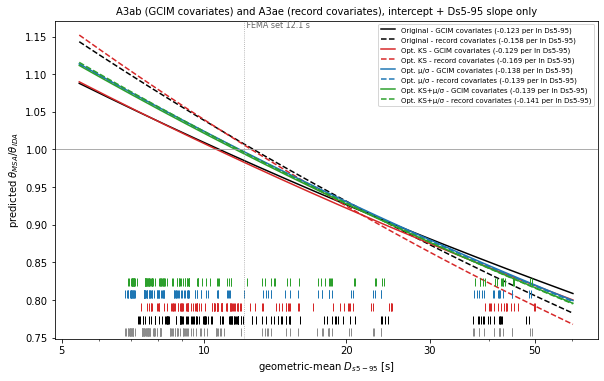

Original - GCIM covariates          slope -0.07346 per SD (SE 0.00323), -0.12336 per unit ln Ds5-95 (covariate SD 0.5955)
Original - record covariates        slope -0.08297 per SD (SE 0.00383), -0.15765 per unit ln Ds5-95 (covariate SD 0.5263)
Opt. KS - GCIM covariates           slope -0.07657 per SD (SE 0.00322), -0.12859 per unit ln Ds5-95 (covariate SD 0.5955)
Opt. KS - record covariates         slope -0.09103 per SD (SE 0.00406), -0.16882 per unit ln Ds5-95 (covariate SD 0.5392)
Opt. μ/σ - GCIM covariates          slope -0.08219 per SD (SE 0.00319), -0.13802 per unit ln Ds5-95 (covariate SD 0.5955)
Opt. μ/σ - record covariates        slope -0.08211 per SD (SE 0.00313), -0.13853 per unit ln Ds5-95 (covariate SD 0.5927)
Opt. KS+μ/σ - GCIM covariates       slope -0.08280 per SD (SE 0.00319), -0.13905 per unit ln Ds5-95 (covariate SD 0.5955)
Opt. KS+μ/σ - record covariates     slope -0.08368 per SD (SE 0.00312), -0.14104 per unit ln Ds5-95 (covariate SD 0.5933)

 Ds5-95 [s]  Original -

In [83]:
# ---- the eight fits in real units: predicted MSA/IDA theta ratio against geometric-mean Ds5-95
# Keep only the intercept m and the mean-Ds5-95 slope of each fit; drop the other three slopes
# without refitting. build_X centred every covariate, so a dropped term contributes exactly 0 at
# that covariate's mean: each line is the prediction for a row average in the other three.
DS_COV = "d_ln_ds595_mean_unif"                    # A3ab's mean-duration covariate (GCIM - FEMA)
fx_ln_ds = comp["fx_ln_ds595_mean"].unique()
assert len(fx_ln_ds) == 1                         # one FEMA set: one constant for every row
fx_ln_ds = float(fx_ln_ds[0])

# (label, summary, fit, covariate, colour, line style): black / red / blue / green = original /
# KS- / mu-sigma- / KS + mu-sigma-optimised records, solid/dashed = GCIM (A3ab) / record (A3ae)
# covariates
LINES = (
    ("Original - GCIM covariates", Sr0, fit_r, DS_COV, "k", "-"),
    ("Original - record covariates", Se0, fit_e, DS_COV_E, "k", "--"),
    ("Opt. KS - GCIM covariates", Sr1, fit_r_s, DS_COV, "C3", "-"),
    ("Opt. KS - record covariates", Se1, fit_e_s, DS_COV_E, "C3", "--"),
    ("Opt. μ/σ - GCIM covariates", Sr2, fit_r_m, DS_COV, "C0", "-"),
    ("Opt. μ/σ - record covariates", Se2, fit_e_m, DS_COV_E, "C0", "--"),
    ("Opt. KS+μ/σ - GCIM covariates", Sr3, fit_r_k, DS_COV, "C2", "-"),
    ("Opt. KS+μ/σ - record covariates", Se3, fit_e_k, DS_COV_E, "C2", "--")
    )


def z_of(ds_s, fit, cov):
    """Standardised covariate for geometric-mean durations ds_s [s], with the fit's OWN scaling.

    Every covariate here is 'ln D - ln D_FEMA' (target-side or record-side), so a duration D maps
    to x = ln D - ln D_FEMA in any fit; only the centring and scaling build_X applied differ.
    """
    s = fit.scaling[cov]
    return (np.log(ds_s) - fx_ln_ds - s["mean"]) / s["sd"]


def per_unit_ln(S, fit, cov):
    """Slope per unit ln Ds5-95: the per-SD slope over the covariate's SD (comparable across fits)."""
    return S[cov] / fit.scaling[cov]["sd"]


def rug_ds(fit, cov):
    """The rows' geometric-mean Ds5-95 [s] behind a fit's covariate: exp(x + ln D_FEMA)."""
    return np.exp(fit.contrast.rows[cov].to_numpy(dtype=float) + fx_ln_ds)


# rugs: grey = GCIM target (identical for every record set), black / red / blue / green =
# original / KS- / mu-sigma- / KS + mu-sigma-optimised records
RUGS = ((rug_ds(fit_r, DS_COV), "0.55", 0.02),
        (rug_ds(fit_e, DS_COV_E), "k", 0.06),
        (rug_ds(fit_e_s, DS_COV_E), "C3", 0.10),
        (rug_ds(fit_e_m, DS_COV_E), "C0", 0.14),
        (rug_ds(fit_e_k, DS_COV_E), "C2", 0.18))
lo = min(r.min() for r, _, _ in RUGS)
hi = max(r.max() for r, _, _ in RUGS)
ds_g = np.geomspace(0.8 * lo, 1.2 * hi, 300)       # a little beyond the rows, even in log(Ds)

fig, ax = plt.subplots(figsize=(8.5, 5.4))
for lab_, S, fit, cov, col, ls in LINES:
    ax.plot(ds_g, np.exp(S["m"] + S[cov] * z_of(ds_g, fit, cov)), color=col, ls=ls,
            label=f"{lab_} ({per_unit_ln(S, fit, cov):+.3f} per ln Ds5-95)")
for ds_r, col, y in RUGS:
    ax.plot(ds_r, np.full_like(ds_r, y), "|", color=col, ms=8, transform=ax.get_xaxis_transform())
ax.axhline(1, color="0.6", lw=0.8)
ax.axvline(np.exp(fx_ln_ds), color="0.6", ls=":", lw=0.8)
ax.text(np.exp(fx_ln_ds), ax.get_ylim()[1], f" FEMA set {np.exp(fx_ln_ds):.1f} s",
        va="top", fontsize=8, color="0.4")
ax.set_xscale("log")
ax.set_xticks([5, 10, 20, 30, 50], ["5", "10", "20", "30", "50"])
ax.set_xlabel(r"geometric-mean $D_{s5-95}$ [s]")
ax.set_ylabel(r"predicted $\theta_{MSA} / \theta_{IDA}$")
ax.set_title("A3ab (GCIM covariates) and A3ae (record covariates), intercept + Ds5-95 slope only",
             fontsize=10)
ax.legend(fontsize=7, loc="upper right")
fig.tight_layout()
savefig(fig, "step4c_a3ab_a3ae_ds595_ratio.png")
plt.show()

# the numbers behind the figure at five durations: the GCIM-target range, 10 s, the FEMA set, 20 s
ds_t = RUGS[0][0]
pick = np.array([float(ds_t.min()), 10.0, float(np.exp(fx_ln_ds)), 20.0, float(ds_t.max())])
tab = pd.DataFrame({"Ds5-95 [s]": pick})
for lab_, S, fit, cov, _, _ in LINES:
    tab[lab_] = np.exp(S["m"] + S[cov] * z_of(pick, fit, cov))
# optimised vs original, per model (same covariate type)
tab["change GCIM cov. [%]"] = 100 * (tab["Opt. KS - GCIM covariates"] / tab["Original - GCIM covariates"] - 1)
tab["change record cov. [%]"] = 100 * (tab["Opt. KS - record covariates"] / tab["Original - record covariates"] - 1)
tab["μ/σ change GCIM cov. [%]"] = 100 * (tab["Opt. μ/σ - GCIM covariates"] / tab["Original - GCIM covariates"] - 1)
tab["μ/σ change record cov. [%]"] = 100 * (tab["Opt. μ/σ - record covariates"] / tab["Original - record covariates"] - 1)
tab["KS+μ/σ change GCIM cov. [%]"] = 100 * (tab["Opt. KS+μ/σ - GCIM covariates"] / tab["Original - GCIM covariates"] - 1)
tab["KS+μ/σ change record cov. [%]"] = 100 * (tab["Opt. KS+μ/σ - record covariates"] / tab["Original - record covariates"] - 1)

for lab_, S, fit, cov, _, _ in LINES:
    print(f"{lab_:35s} slope {S[cov]:+.5f} per SD (SE {S[f'se_{cov}']:.5f}), "
          f"{per_unit_ln(S, fit, cov):+.5f} per unit ln Ds5-95 (covariate SD {fit.scaling[cov]['sd']:.4f})")
print()
print(tab.round(4).to_string(index=False))


**Step 4d reading.**

* **Regression checks pass.** `rsc.record_covariates` reproduces nb 072's four `_unif_corrected`
  columns on the original sets (atol $10^{-10}$), and A3ae on the original θ reproduces nb 073
  (Ds5-95 mean slope −0.08297 per SD, $\tau_s$ 0.0302).
* **The optimised records move the record covariates mainly in their spread.**
  * SD(ln Ds5-95) rises by a mean of +0.117 over the 120 rows (median +0.117).
  * Mean ln Ds5-95 rises by +0.020.
  * The two SaRatio covariates barely move (mean shifts −0.001 and +0.012).
  * This is Step 2's heavier duration tail, now seen at row level.
* **The A3ae mean-duration slope moves by more than 0.5 SE.**
  * Per SD it goes from −0.0830 to −0.0910, i.e. **−2.10 SE**.
  * The covariate's SD also changed (0.526 → 0.539), so the per-unit-ln comparison is the fair one:
    −0.158 → **−0.169 per unit ln Ds5-95**, ≈ −1.5 original SE.
  * Either way it is over the threshold, and larger than A3ab's shift (−0.123 → −0.129 per unit ln,
    −0.96 SE).
* **The SD(ln Ds5-95) slope** goes from −0.0139 to −0.0186 per SD (**−1.20 SE**). Its CI excludes 0
  before and after.
* **No other A3ae quantity crosses 0.5 SE.** $m$: −0.29 SE; $\tau_s$: +0.42 SE. **No qualitative
  check changed**: every slope keeps its sign and its CI-includes-0 status.
* **In ratio terms the change is small.**
  * Doubling the duration lowers the predicted MSA/IDA ratio by 10.4 % (original) and 11.0 %
    (optimised).
  * At the table's durations, the record-covariate line moves by −1.7 % (49 s) to +0.5 % (6.8 s).
  * The GCIM-covariate line moves by −1.0 % to +0.1 %.
* **Caveat.** The covariates are recomputed exactly from the optimised records, but the optimised
  $y$ is still the Step 3 logistic surrogate ($a_i + \Delta a_i$), not new NLTHA. So the slope shift
  combines an exact covariate change with a modelled outcome change.


## 5 — Summary

Every quantity of the study-level fits, its shift in units of the original fit's SE, and
whether that is over or under the 0.5 SE threshold; then every qualitative check, changed or
unchanged. Every shift is against the same model fitted to the original record sets.

| fit | record sets | parameter | quantities |
|---|---|---|---|
| `A0c_hb` (Step 4) | Opt. KS | θ | $m_0$, $\tau_d$, $\tau_s$, $\tau_u$ |
| `A0c_bc_hb` (Step 4b) | Opt. KS | β | $m_0$, $\tau_d$, $\tau_s$, $\tau_u$ |
| `A3ab` (Step 4c) | Opt. KS, Opt. μ/σ, Opt. KS+μ/σ | θ | $m$, $\tau_d$, $\tau_s$, $\tau_u$, four slopes (GCIM covariates) |
| `A3ae` (Step 4d) | Opt. KS, Opt. μ/σ, Opt. KS+μ/σ | θ | $m$, $\tau_d$, $\tau_s$, $\tau_u$, four slopes (record covariates) |


In [ ]:
# ---- every quantity of every study-level fit against the 0.5-SE threshold (D1)
# (record sets, parameter, model, shift table, qualitative checks); every shift is against the
# fit on the ORIGINAL record sets. The A0c fits exist for the KS-optimised sets only (Step 3b
# took no coefficient draws and Step 4/4b were not repeated for mu/sigma).
FITS = (#("Opt. KS", "theta", rsc.A0C_HB, shift, qual),
        #("Opt. KS", "beta", rsc.A0C_BC_HB, shift_b, qual_b),
        ("Opt. KS", "theta", rsc.A3AB, shift_r, qual_r),
        ("Opt. KS", "theta", rsc.A3AE, shift_e, qual_e),
        ("Opt. mu/sigma", "theta", rsc.A3AB, shift_r_m, qual_r_m),
        ("Opt. mu/sigma", "theta", rsc.A3AE, shift_e_m, qual_e_m),
        ("Opt. KS+mu/sigma", "theta", rsc.A3AB, shift_r_k, qual_r_k),
        ("Opt. KS+mu/sigma", "theta", rsc.A3AE, shift_e_k, qual_e_k))

summary = pd.concat([sh.assign(records=rs, parameter=par, model=mid) for rs, par, mid, sh, _ in FITS],
                    ignore_index=True)
summary["vs_threshold"] = np.where(summary.exceeds_threshold, "over 0.5 SE", "under 0.5 SE")
summary = summary[["records", "model", "parameter", "quantity", "original", "shifted", "delta",
                   "se_original", "delta_over_se", "vs_threshold", "ratio_change"]]
summary.to_csv(OUT / "step5_threshold_summary.csv", index=False)
print(summary.round(4).to_string(index=False))

checks = pd.concat([ql.assign(records=rs, parameter=par, model=mid) for rs, par, mid, _, ql in FITS],
                   ignore_index=True)[["records", "model", "parameter", "check", "original", "shifted",
                                       "changed"]]
checks.to_csv(OUT / "step5_qualitative_summary.csv", index=False)

# one line per fit: which quantities are over the threshold, which checks changed
print()
for rs, par, mid, sh, ql in FITS:
    over = sh.loc[sh.exceeds_threshold, "quantity"].tolist()
    changed = ql.loc[ql.changed, "check"].tolist()
    print(f"{rs:16s} {mid} ({par}): over 0.5 SE: {over or 'none'}; "
          f"qualitative checks changed: {changed or 'none'}")

# Delta / SE side by side: one column per (record sets, model), one row per quantity
print()
print(summary.pivot_table(index="quantity", columns=["records", "model"], values="delta_over_se",
                          sort=False).round(2).to_string())

print(f"\nm0 as a ratio, theta (A0c_hb):   exp(m0) {np.exp(S0['m']):.4f} -> {np.exp(S1['m']):.4f} "
      f"({shift.set_index('quantity').loc['m', 'ratio_change']:+.2%})")
# Step 4b (beta) is currently commented out; print its line only when it has been run
if "Sb0" in globals():
    print(f"m0 as a ratio, beta (A0c_bc_hb): exp(m0) {np.exp(Sb0['m']):.4f} -> {np.exp(Sb1['m']):.4f} "
          f"({shift_b.set_index('quantity').loc['m', 'ratio_change']:+.2%})")


         records model parameter                          quantity  original  shifted   delta  se_original  delta_over_se vs_threshold  ratio_change
         Opt. KS  A3ab     theta                                 m   -0.0095  -0.0117 -0.0021       0.0197        -0.1079 under 0.5 SE       -0.0021
         Opt. KS  A3ab     theta                             tau_d    0.0111   0.0070 -0.0041       0.0117        -0.3506 under 0.5 SE           NaN
         Opt. KS  A3ab     theta                             tau_s    0.0416   0.0424  0.0009       0.0038         0.2266 under 0.5 SE           NaN
         Opt. KS  A3ab     theta                             tau_u    0.0153   0.0188  0.0035       0.0050         0.6916  over 0.5 SE           NaN
         Opt. KS  A3ab     theta            d_ln_saratio_mean_unif    0.0086   0.0062 -0.0024       0.0053        -0.4547 under 0.5 SE           NaN
         Opt. KS  A3ab     theta              d_ln_ds595_mean_unif   -0.0735  -0.0766 -0.0031       0.0032

**Result.** Shift / original SE, against the 0.5 SE threshold.

| quantity | A0c_hb (θ) | A0c_bc_hb (β) | A3ab (θ) |
|---|---|---|---|
| $m$ | −0.14, under | **+0.56, over** | −0.10, under |
| $\tau_d$ | −0.11, under | 0.00, under (at zero throughout) | −0.40, under |
| $\tau_s$ | +0.47, under | −0.41, under | +0.23, under |
| $\tau_u$ | +0.34, under | 0.00, under (at zero throughout) | **+0.71, over** |
| slope, $\Delta E[\ln \mathrm{SaRatio}]$ | — | — | −0.45, under |
| slope, $\Delta E[\ln D_{s5-95}]$ | — | — | **−0.97, over** |
| slope, $\Delta SD[\ln \mathrm{SaRatio}]$ | — | — | +0.23, under |
| slope, $\Delta SD[\ln D_{s5-95}]$ | — | — | −0.32, under |

* **Over 0.5 SE:** β's $m_0$ (A0c_bc_hb); $\tau_u$ and the $\Delta E[\ln D_{s5-95}]$ slope (A3ab).
* **Qualitative checks:** none changed in any of the three fits. In A3ab every slope keeps its
  sign; the $\Delta E[\ln D_{s5-95}]$ slope's CI excludes 0 before and after (−0.0735 → −0.0766
  per SD), and the other three slopes' CIs include 0 before and after.
* **$m_0$ as a ratio:** θ 1.0068 → 1.0035 (−0.33 %); β 1.016 → 1.044 (+2.8 %).
* **SEs differ in kind between the fits.** A0c_hb and A0c_bc_hb use superpopulation SEs (hybrid
  bootstrap); A3ab uses record-only SEs, which are narrower (e.g. $\tau_u$: 0.0050 in A3ab
  against 0.0066 in A0c_hb).
* θ's propagated logistic-uncertainty ranges (A0c_hb only): $\tau_s$ +0.36 to +0.58,
  $\tau_u$ +0.13 to +0.65 SE.

Tables: `step5_threshold_summary.csv`, `step5_qualitative_summary.csv`.
